# Leaf Game: CCA spectra and behavior - 4 November 2026

Participant **7**, four official blocks, **96 trials**: 12 C1 pointing and 12 C2 motion per block.
Low = **17 Hz**, high = **19 Hz**. Assignments to C1/C2 swap across trials; use each trial's
logged frequencies, never the old 15/17 Hz defaults.

| Block | EEG session | Behavioral log |
|---|---|---|
| 1 | eeg_20261104_162610 | p7_b1_leaves_trialdata.csv |
| 2 | eeg_20261104_163332 | p7_b2_leaves_trialdata.csv |
| 3 | eeg_20261104_164709 | p7_b3_leaves_trialdata.csv |
| 4 | eeg_20261104_165657 | p7_b4_leaves_trialdata.csv |

**Cleanup:** Before user removal, 16:19:39 contained 93,957 EEG samples and 24 trials with
markers 20/21/39/40/41/42/30, matching the Paddle MultiDir protocol rather than these Leaf logs.
16:40:51 contained 72,215 EEG samples (288.86 s), all markers zero. Neither was empty EEG.
The user deleted these extras. This notebook never deletes inputs. Header-only raw CSVs
are normal PROC ONLY logger placeholders and remain in the four retained sessions.

This preserves the reference's per-channel, arithmetic channel mean, whole-recording CCA and
rolling 1-second CCA views separately for each block. Continuous views include setup, rest,
feedback and intertrial periods. Condition analysis uses marker-delimited **cue-to-color onset**
intervals, or cue-to-stop for reveal timeouts, with CCA fitted independently inside each trial.

Stored board-filtered microvolts, C9-C16 by default; no added filtering, CAR, rejection or
interpolation. **5-second epochs, DPSS NW=1/K=1, 0.2 Hz FFT grid**; partial tails retained
as trailing NaNs. PSDs are averaged in linear power, with equal trial weights for condition views.
PSD of the mean epoch waveform is descriptive, **not an evoked response**: trials are not
flicker-phase aligned. Independent 17/19 Hz CCA references use unit-norm weights and the
same data as the plotted spectra; target peaks do not validate decoding or attention.
Channel mean and CCA use different power normalization.

Rolling CCA reconstructs logged update endpoints plus boundary fits. Its initial 1-second fit
projects back across its own samples, using look-ahead. Condition fits never cross trials.
These are descriptive results for one participant, without population inference.

In [1]:
from pathlib import Path
from functools import lru_cache
import base64,hashlib,html,json,re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import HTML,display
ROOT=Path.cwd()
if not (ROOT/'data/2026-11-04').is_dir():ROOT=Path(r'C:\Users\Kalyanbrata\Documents\Android\Analysis')
DATA_ROOT=ROOT/'data/2026-11-04'
BLOCK_SESSIONS={1:'eeg_20261104_162610',2:'eeg_20261104_163332',3:'eeg_20261104_164709',4:'eeg_20261104_165657'}
SESSION_IDS=list(BLOCK_SESSIONS.values())
FS,TARGETS_HZ=250.,(17.,19.)
EPOCH_SECONDS=5.;EPOCH_SAMPLES=int(FS*EPOCH_SECONDS)
WINDOW_SAMPLES,HOP_SAMPLES=250,25
RECORDED_CHANNEL_NAMES=[f'C{i}' for i in range(9,17)]
RECORDED_CHANNEL_COLUMNS=[f'ch{i}_uv' for i in range(9,17)]
CHANNEL_PSD_FREQ_LIMITS,FREQ_LIMITS=(5.,40.),(5.,30.)
PLOT_EXPORT_DPI=160
EXPORT_ROOT=ROOT/'plots'/f'2026-11-04_leaf_overview_{EPOCH_SECONDS:g}s'
EXPORT_ROOT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':100,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.18,'font.size':10})

## Read CSVs, match all 24 starts per block and audit coverage

Markers persist across samples. An event is the **first sample of each new nonzero marker run**.
Local `SsvepFrequencyAssignment.StartMarker = 31 + cueIndex + (swapped ? 2 : 0)` gives:

| Marker | Cue | C1 Hz | C2 Hz | Attended Hz |
|---|---|---:|---:|---:|
| 31 | C1 | 17 | 19 | 17 |
| 32 | C2 | 17 | 19 | 19 |
| 33 | C1 | 19 | 17 | 19 |
| 34 | C2 | 19 | 17 | 17 |

**50 = color reveal; 40 = response; 30 = trial stop.** These cue-first logs have cue onset at
trial start, without a separate marker 45. Exact marker order must match the behavioral logs.
EEG sequence numbers define sample time. Config counters can exceed CSV rows by a few
terminal samples: the actual coverage and discrepancy are reported without fabricating data.

In [2]:
MARKER_MAP={31:('c1',17.,19.),32:('c2',17.,19.),33:('c1',19.,17.),34:('c2',19.,17.)}
records=[];recording_rows=[];input_hashes=[];behaviors=[];event_tables=[]
for block,session_id in BLOCK_SESSIONS.items():
 folder=DATA_ROOT/session_id
 config=(folder/f'{session_id}_config.txt').read_text(encoding='utf-8-sig')
 assert re.search(r'Sampling Rate.*?:\s*250 Hz',config)
 frame=pd.read_csv(folder/f'{session_id}_signals.csv',encoding='utf-8-sig')
 features=pd.read_csv(folder/f'{session_id}_features.csv',encoding='utf-8-sig')
 seq=frame['seq'].to_numpy(dtype=np.int64);x=frame[RECORDED_CHANNEL_COLUMNS].to_numpy(float)
 markers=frame.marker.to_numpy(dtype=np.int64)
 assert np.isfinite(x).all() and np.all(np.diff(seq)==1)
 idx=np.flatnonzero(np.r_[True,markers[1:]!=markers[:-1]] & (markers!=0))
 events=pd.DataFrame(dict(block=block,session=session_id,position=idx,seq=seq[idx],eeg_seconds=idx/FS,marker=markers[idx]))
 starts=events[events.marker.isin(MARKER_MAP)].reset_index(drop=True)
 trials=pd.read_csv(DATA_ROOT/'gameData'/f'p7_b{block}_leaves_trialdata.csv')
 assert len(trials)==len(starts)==24 and trials.TrialNumber.tolist()==list(range(1,25))
 assert starts.marker.tolist()==trials.TrialStartMarker.tolist()
 assert set(events.marker)<=set(MARKER_MAP)|{30,40,50}
 assert np.allclose(trials.CueOnsetTime,trials.TrialStart)
 assert trials.groupby(['Cue','FrequenciesSwapped']).size().eq(6).all()
 for row in trials.itertuples():
  assert MARKER_MAP[row.TrialStartMarker]==(row.Cue,row.FrequencyC1Hz,row.FrequencyC2Hz)
  assert row.TrialStartMarker==31+(row.Cue=='c2')+2*row.FrequenciesSwapped
  assert row.NFIndexUsed==(1 if (row.FrequencyC1Hz if row.Cue=='c1' else row.FrequencyC2Hz)==17 else 2)
 trials['block']=block;trials['session']=session_id
 trials['attended_hz']=np.where(trials.Cue.eq('c1'),trials.FrequencyC1Hz,trials.FrequencyC2Hz)
 trials['distractor_hz']=np.where(trials.attended_hz.eq(17),19.,17.)
 trials['start_pos']=starts.position.to_numpy();trials['start_seq']=starts.seq.to_numpy()
 trials['clock_offset_seconds']=starts.eeg_seconds.to_numpy()-trials.TrialStart.to_numpy()
 trials['reveal_wait_seconds']=trials.ColorOnsetTime-trials.TrialStart
 trials['trial_duration_seconds']=trials.TrialEnd-trials.TrialStart
 trials['valid_response']=trials.ParticipantResponse.isin(['up','down','left','right']) & trials.ReactionTime.ge(0) & trials.RevealTimeout.eq(0) & trials.ResponseTimeout.eq(0)
 valid=trials[trials.valid_response]
 assert np.array_equal(valid.Accuracy.eq(1),(valid.ParticipantResponse==valid.CorrectResponse))
 nfseq=np.unique(features.loc[features.is_cca.eq(1),'seq'].to_numpy(dtype=np.int64))
 config_samples=int(re.search(r'Filtered Signals\s*:\s*([\d,]+)',config)[1].replace(',',''))
 recording_rows.append(dict(block=block,session=session_id,samples=len(x),observed_seconds=len(x)/FS,channels=x.shape[1],first_seq=int(seq[0]),last_seq=int(seq[-1]),gap_events=int(np.count_nonzero(np.diff(seq)!=1)),config_signal_samples=config_samples,config_minus_csv_samples=config_samples-len(x),trials=len(starts),cca_updates=len(nfseq),clock_offset_first=trials.clock_offset_seconds.iloc[0],clock_offset_last=trials.clock_offset_seconds.iloc[-1]))
 records.append(dict(block=block,session=session_id,label=f'Leaf block {block}',source='board-filtered',recorded_x=x,seq=seq,markers=markers,nfseq=nfseq,events=events,behavior=trials))
 behaviors.append(trials);event_tables.append(events)
 for path in sorted(folder.iterdir()):
  if path.is_file():input_hashes.append(dict(file=str(path.relative_to(DATA_ROOT)),bytes=path.stat().st_size,sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
for path in sorted((DATA_ROOT/'gameData').glob('*.csv')):
 input_hashes.append(dict(file=str(path.relative_to(DATA_ROOT)),bytes=path.stat().st_size,sha256=hashlib.sha256(path.read_bytes()).hexdigest()))
recording_audit=pd.DataFrame(recording_rows);behavior=pd.concat(behaviors,ignore_index=True)
recording_audit.to_csv(EXPORT_ROOT/'recording_audit.csv',index=False)
pd.concat(event_tables).to_csv(EXPORT_ROOT/'marker_events.csv',index=False)
pd.DataFrame(input_hashes).to_csv(EXPORT_ROOT/'input_sha256.csv',index=False)
display(recording_audit)

,block,session,samples,observed_seconds,channels,first_seq,last_seq,gap_events,config_signal_samples,config_minus_csv_samples,trials,cca_updates,clock_offset_first,clock_offset_last
0,1,eeg_20261104_162610,106759,427.036,8,500347,607105,0,106762,3,24,4271,61.655017,61.149948
1,2,eeg_20261104_163332,104237,416.948,8,610725,714961,0,104238,1,24,4170,22.938443,22.388171
2,3,eeg_20261104_164709,116070,464.280,8,814650,930719,0,116073,3,24,4643,76.941433,76.380493
3,4,eeg_20261104_165657,136878,547.512,8,961423,1098300,0,136880,2,24,5475,189.682403,189.193214


## Spectral estimator from the reference notebook

Epoch the complete session with NaN tails; PSD calculations use observed samples only.
A partial epoch has equal weight but lower true resolution despite the shared FFT grid.
Waveform-first averaging uses only observed epochs at each sample position.

In [3]:
"""NaN-aware spectra for the configured epoch duration."""
import numpy as np
from scipy import signal

def epoch_trials(waveforms, epoch_samples):
    """Trial x epoch x sample [x projection]; retain every observed sample."""
    waves = [np.asarray(w, float) for w in waveforms]
    if not waves or epoch_samples < 2 or any(not np.isfinite(w).all() for w in waves):
        raise ValueError('Need nonempty, finite observed trials and a valid epoch length')
    tail_shape = waves[0].shape[1:]
    if any(w.shape[1:] != tail_shape for w in waves):
        raise ValueError('Projection shapes differ between trials')
    count = max((len(w)+epoch_samples-1)//epoch_samples for w in waves)
    result = np.full((len(waves), count, epoch_samples, *tail_shape), np.nan)
    for j, wave in enumerate(waves):
        for k, start in enumerate(range(0, len(wave), epoch_samples)):
            block = wave[start:start+epoch_samples]
            result[j, k, :len(block)] = block
    return result

def nan_epoch_psd(epoch, fs, epoch_samples):
    """Missing tails never enter detrending/tapering; common configured-length FFT grid."""
    x = np.asarray(epoch, float)
    valid = np.isfinite(x if x.ndim == 1 else x[:, 0])
    length = int(valid.sum())
    if not np.array_equal(valid, np.arange(len(x)) < length):
        raise ValueError('Only trailing NaNs are supported')
    f = np.fft.rfftfreq(epoch_samples, d=1/fs)
    if length < 2:
        return f, np.full((len(f), *x.shape[1:]), np.nan)
    observed = x[:length]
    if not np.isfinite(observed).all():
        raise ValueError('Inconsistent missing data across projections')
    # A 2-sample final fragment cannot support NW=1; use the largest legal NW.
    taper = signal.windows.dpss(length, NW=min(1., (length-1)/2), Kmax=1, sym=False)[0]
    return signal.periodogram(observed, fs=fs, window=taper, nfft=epoch_samples,
                              detrend='constant', scaling='density', axis=0)

def finite_mean(values, axis=0):
    values = np.asarray(values, float)
    count = np.isfinite(values).sum(axis=axis)
    total = np.nansum(values, axis=axis)
    return np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)

def pooled_trial_spectrum_orders(padded, fs):
    """Two epoch orders, with equal trial weighting in both operations."""
    n = padded.shape[2]
    epoch_power = np.stack([np.stack([nan_epoch_psd(e, fs, n)[1] for e in trial]) for trial in padded])
    # First average a trial's observed epoch spectra; then average trials equally.
    trial_power = finite_mean(epoch_power, axis=1)
    power_first = finite_mean(trial_power, axis=0)
    # First form each trial's NaN-aware mean epoch; then average those trials.
    trial_mean_epochs = finite_mean(padded, axis=1)
    mean_epoch = finite_mean(trial_mean_epochs, axis=0)
    f, waveform_first = nan_epoch_psd(mean_epoch, fs, n)
    counts = np.isfinite(trial_mean_epochs[..., 0] if trial_mean_epochs.ndim == 3 else trial_mean_epochs).sum(axis=0)
    return dict(f=f, induced=power_first, evoked=waveform_first, mean_epoch=mean_epoch,
                counts=counts, trial_power=trial_power, epoch_power=epoch_power)

## Inspect C9-C16 for each official block

Continuous spectra include setup and intertrial periods. Dotted lines mark 17/19 Hz.


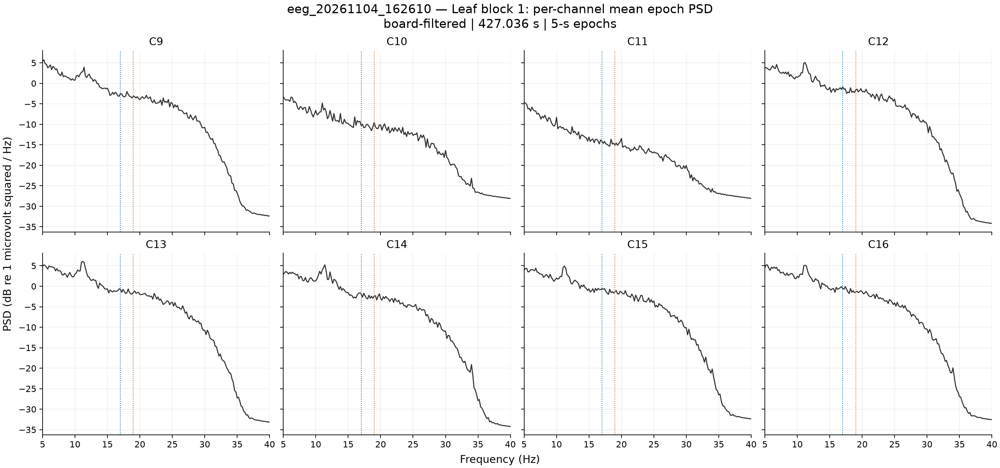


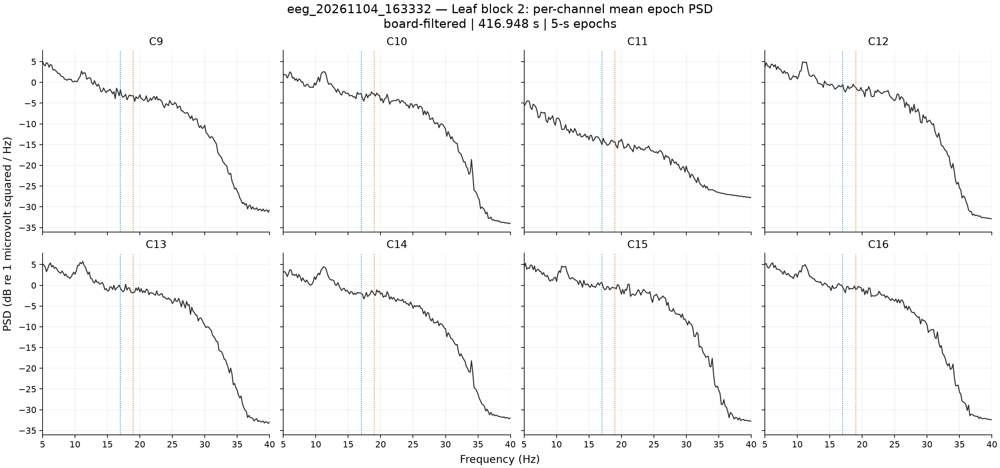


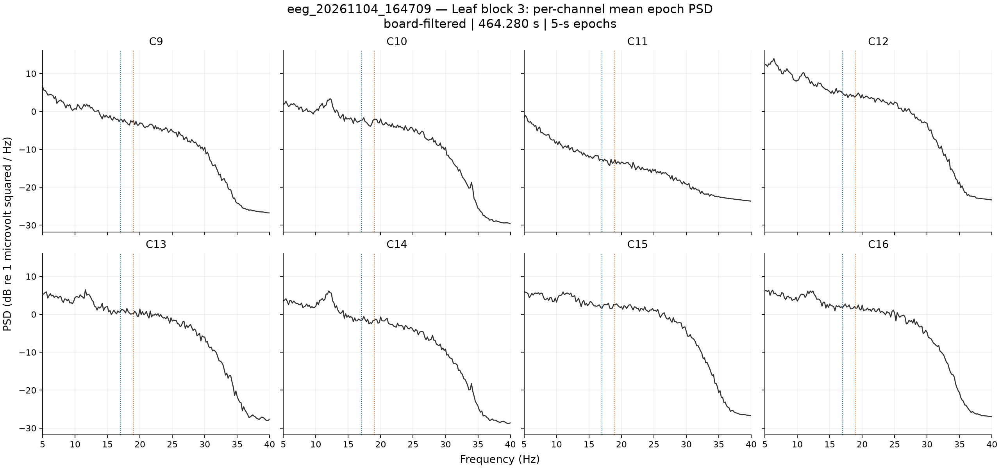


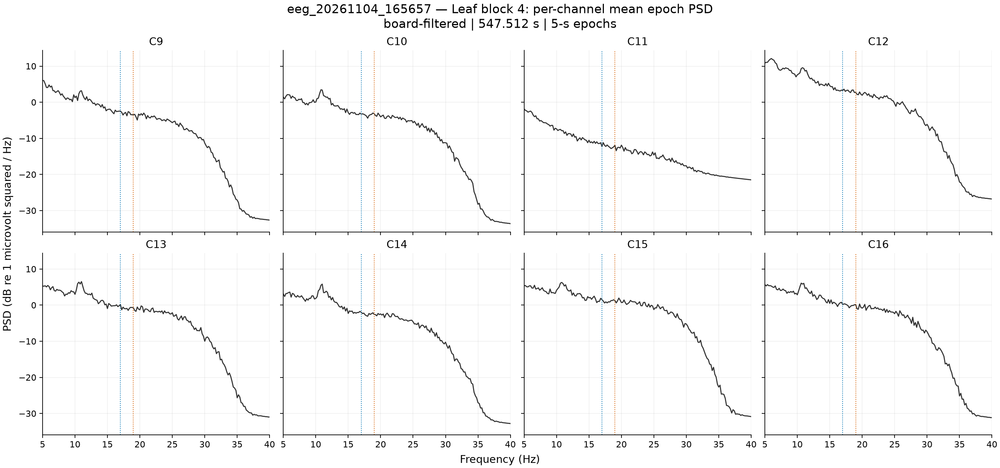

In [4]:
def db_plot(power):
    power = np.asarray(power, float)
    return 10*np.log10(np.where(power>0, power, np.nan))
def limits_for(powers):
    values = np.concatenate([db_plot(p).ravel() for p in powers])
    values = values[np.isfinite(values)]
    if not len(values): return (-1,1)
    lo, hi = values.min(), values.max()
    pad = max((hi-lo)*.05,1.)
    return lo-pad, hi+pad

plot_exports = []
def save_figure(fig, rec, stem, title, caption, view, method, order, folder):
    folder.mkdir(parents=True, exist_ok=True)
    png, svg = folder / f'{stem}.png', folder / f'{stem}.svg'
    fig.savefig(png, dpi=PLOT_EXPORT_DPI)
    fig.savefig(svg)
    plt.close(fig)
    plot_exports.append(dict(session=rec['session'], label=rec['label'], source=rec['source'], view=view,
        method=method, order=order, title=title, caption=caption,
        selected_channels=', '.join(CHANNEL_NAMES) if view!='per_channel' else ', '.join(RECORDED_CHANNEL_NAMES),
        png=png.relative_to(EXPORT_ROOT).as_posix(), svg=svg.relative_to(EXPORT_ROOT).as_posix()))
    encoded = base64.b64encode(png.read_bytes()).decode('ascii')
    return (f'<img src="data:image/png;base64,{encoded}" style="width:100%;height:auto" alt="{html.escape(title)}">'
        f'<p>{html.escape(caption)}</p><a href="{png.relative_to(ROOT).as_posix()}">PNG</a> | '
        f'<a href="{svg.relative_to(ROOT).as_posix()}">SVG</a>')

variability_rows, per_channel_numeric = [], []
for rec in records:
    x = rec['recorded_x']
    rec['channel_summary'] = pooled_trial_spectrum_orders(epoch_trials([x],EPOCH_SAMPLES), FS)
    summary = rec['channel_summary']
    f, power = summary['f'], summary['induced']
    mask = (f>=CHANNEL_PSD_FREQ_LIMITS[0]) & (f<=CHANNEL_PSD_FREQ_LIMITS[1])
    fig, axes = plt.subplots(2,4,figsize=(16,7.5),sharex=True,sharey=True,constrained_layout=True)
    ylim = limits_for([power[mask]])
    for j,(channel,ax) in enumerate(zip(RECORDED_CHANNEL_NAMES,axes.flat)):
        flat = bool(np.ptp(x[:,j])==0)
        variability_rows.append(dict(session=rec['session'], source=rec['source'], channel=channel,
            samples=len(x), std_uv=float(np.std(x[:,j])), peak_to_peak_uv=float(np.ptp(x[:,j])), flat=flat))
        ax.plot(f[mask],db_plot(power[mask,j]),color='#333333',lw=1.2)
        for hz,color in zip(TARGETS_HZ,('#0072B2','#D55E00')):
            ax.axvline(hz,color=color,ls=':',lw=.9)
        if flat: ax.text(.5,.5,'No measurable variance',transform=ax.transAxes,ha='center')
        ax.set(title=channel,xlim=CHANNEL_PSD_FREQ_LIMITS,ylim=ylim)
        per_channel_numeric.append(pd.DataFrame(dict(session=rec['session'],source=rec['source'],
            channel=channel,frequency_hz=f,power_uv2_per_hz=power[:,j])))
    title = f'{rec["session"]} — {rec["label"]}: per-channel mean epoch PSD'
    fig.suptitle(f'{title}\n{rec["source"]} | {len(x)/FS:.3f} s | {EPOCH_SECONDS:g}-s epochs',fontsize=14)
    fig.supxlabel('Frequency (Hz)')
    fig.supylabel('PSD (dB re 1 microvolt squared / Hz)')
    caption = (f'{rec["source"]}. All samples retained. {len(x)//EPOCH_SAMPLES} complete + '
        f'{int(bool(len(x)%EPOCH_SAMPLES))} partial epochs. Mean epoch PSD in linear power, each channel separately. '
        f'DPSS NW=1/K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid. Dotted blue/orange: 17/19 Hz analysis targets.')
    panel = save_figure(fig,rec,'per_channel_mean_epoch_psd',title,caption,'per_channel',
        'independent_channels','spectrum_first',EXPORT_ROOT / rec['session'])
    display(HTML(f'<h3>{html.escape(rec["session"])} — {html.escape(rec["label"])}</h3>{panel}'))
pd.DataFrame(variability_rows).to_csv(EXPORT_ROOT / 'per_channel_variability_audit.csv',index=False)
pd.concat(per_channel_numeric,ignore_index=True).to_csv(EXPORT_ROOT / 'per_channel_average_spectra.csv',index=False)

## Select channels for means and CCA

Edit the list and rerun this cell and everything below it. Inspection grids retain all channels.
Each selection has a separate results subfolder per session. C16 anchors CCA polarity when
selected; otherwise the largest absolute coefficient anchors polarity, as in the reference.

In [5]:
SELECTED_CHANNELS = ['C9','C10','C11','C12','C13','C14','C15','C16']
if (not isinstance(SELECTED_CHANNELS,(list,tuple)) or not SELECTED_CHANNELS or
        not all(isinstance(c,str) and c in RECORDED_CHANNEL_NAMES for c in SELECTED_CHANNELS) or
        len(set(SELECTED_CHANNELS))!=len(SELECTED_CHANNELS)):
    raise ValueError('Use a nonempty list of unique channel names from C9-C16')
CHANNEL_NAMES = list(SELECTED_CHANNELS)
SELECTED_CHANNEL_INDICES = [RECORDED_CHANNEL_NAMES.index(c) for c in CHANNEL_NAMES]
CHANNEL_COLUMNS = [RECORDED_CHANNEL_COLUMNS[i] for i in SELECTED_CHANNEL_INDICES]
SIGN_ANCHOR_INDEX = CHANNEL_NAMES.index('C16') if 'C16' in CHANNEL_NAMES else None
CHANNEL_LIST_TEXT = ', '.join(CHANNEL_NAMES)
SELECTION_TAG = 'channels_' + '_'.join(c[1:] for c in CHANNEL_NAMES)
for rec in records:
    rec['x'] = np.ascontiguousarray(rec['recorded_x'][:,SELECTED_CHANNEL_INDICES])
    rec['export_dir'] = EXPORT_ROOT / rec['session'] / SELECTION_TAG
    rec['export_dir'].mkdir(parents=True,exist_ok=True)
    selection = dict(session=rec['session'],label=rec['label'],selected_channels=CHANNEL_NAMES,
        recorded_channels=RECORDED_CHANNEL_NAMES,sample_rate_hz=FS,epoch_seconds=EPOCH_SECONDS,
        source=rec['source'],raw_preprocessing='counts * metadata uv_per_count; no offline filter',
        polarity_anchor='C16' if SIGN_ANCHOR_INDEX is not None else 'largest absolute coefficient')
    (rec['export_dir'] / 'selected_channels.json').write_text(json.dumps(selection,indent=2),encoding='utf-8')
plot_exports = [p for p in plot_exports if p['view']=='per_channel']
print('Downstream channels:',CHANNEL_LIST_TEXT)

Downstream channels: C9, C10, C11, C12, C13, C14, C15, C16


## Independent 17 Hz and 19 Hz CCA projections

The following CCA implementation and recovery/rank checks come from the reference notebook.
Direct data SVD avoids squaring the condition number. Each target has exactly two sine/cosine
columns and independent unit-norm EEG weights. Rolling fits use complete 1-second windows;
only newly covered samples are assigned. Fit means, weights, bounds, correlations and
endpoint provenance are saved. The raw session remains unfiltered for both CCA methods.

In [6]:
def reference_matrix(time_seconds, frequencies_hz):
    t = np.asarray(time_seconds, dtype=float)
    return np.column_stack([func(2*np.pi*f*t)
                            for f in frequencies_hz for func in (np.sin, np.cos)])

def joint_reference(time_seconds):
    return reference_matrix(time_seconds, TARGETS_HZ)

def whitening_basis(centered):
    # Direct data SVD avoids squaring the condition number through X.T @ X.
    q, singular_values, rotation = np.linalg.svd(centered, full_matrices=False)
    tolerance = max(centered.shape) * np.finfo(float).eps * singular_values[0]
    keep = singular_values > tolerance
    if not np.any(keep):
        raise ValueError('No nonzero variance for CCA')
    return rotation[keep].T / singular_values[keep], q[:, keep]

def fit_cca_projection(eeg_uv, time_seconds, frequencies_hz):
    x, y = np.asarray(eeg_uv, float), reference_matrix(time_seconds, frequencies_hz)
    if x.ndim != 2 or x.shape[0] != y.shape[0] or x.shape[1] != len(CHANNEL_COLUMNS):
        raise ValueError('Expected samples x selected channels and matching reference times')
    if len(x) <= x.shape[1]+y.shape[1] or not np.isfinite(x).all():
        raise ValueError('Insufficient samples or non-finite EEG')
    x_mean, y_mean = x.mean(axis=0), y.mean(axis=0)
    xc, yc = x-x_mean, y-y_mean
    (bx, qx), (by, qy) = whitening_basis(xc), whitening_basis(yc)
    left, strengths, right = np.linalg.svd(qx.T @ qy, full_matrices=False)
    w, v = bx @ left[:, 0], by @ right[0]
    w /= np.linalg.norm(w)
    v /= np.linalg.norm(v)
    anchor = SIGN_ANCHOR_INDEX
    fallback = anchor is None or abs(w[anchor]) <= 1e-12
    if fallback:
        anchor = int(np.argmax(np.abs(w)))
    if w[anchor] < 0:
        w, v = -w, -v
    u = xc @ w
    rho = float(np.corrcoef(u, yc @ v)[0, 1])
    if not np.isfinite(rho):
        raise ValueError('Degenerate projected variance')
    return dict(w=w, v=v, x_mean=x_mean, y_mean=y_mean, u=u, rho=rho,
                rho_svd=float(np.clip(strengths[0], 0, 1)), x_rank=bx.shape[1],
                y_rank=by.shape[1], sign_fallback=fallback,
                frequencies_hz=tuple(frequencies_hz), reference_columns=y.shape[1])

def fit_joint_cca(eeg_uv, time_seconds):
    return fit_cca_projection(eeg_uv, time_seconds, TARGETS_HZ)

def fit_target_cca(eeg_uv, time_seconds, target_hz):
    # Exactly two reference columns; each call estimates its own EEG weights.
    return fit_cca_projection(eeg_uv, time_seconds, (float(target_hz),))

@lru_cache(maxsize=None)
def dpss_taper(n_samples):
    return signal.windows.dpss(n_samples, NW=1, Kmax=1, sym=False)[0]

def psd(data, nfft=None):
    x = np.asarray(data, float)
    return signal.periodogram(x, fs=FS, window=dpss_taper(len(x)), nfft=len(x) if nfft is None else nfft,
        detrend='constant', return_onesided=True, scaling='density', axis=0)

def db(power):
    return 10*np.log10(np.maximum(np.asarray(power), np.finfo(float).tiny))

# Known linear mixture, rank deficiency, scaling, and phase-cancellation checks.
rng = np.random.default_rng(17)
t_test = np.arange(1000)/FS
r_test = joint_reference(t_test)
x_test = r_test @ rng.normal(size=(4, len(CHANNEL_COLUMNS)))
x_test += rng.normal(scale=.01, size=x_test.shape)
fit_test = fit_joint_cca(x_test, t_test)
assert fit_test['rho'] > .999
assert np.isclose(np.linalg.norm(fit_test['w']), 1)
assert np.isclose(fit_test['rho'], fit_test['rho_svd'], atol=1e-10)
assert fit_joint_cca(np.tile(r_test[:, :1], (1, len(CHANNEL_COLUMNS))), t_test)['x_rank'] == 1
assert len(psd(fit_test['u'])[0]) == 501
for target in TARGETS_HZ:
    # A target-specific mixture supports this check even with one selected channel.
    target_ref = reference_matrix(t_test, (target,))
    target_eeg = target_ref @ rng.normal(size=(2, len(CHANNEL_COLUMNS)))
    target_eeg += rng.normal(scale=.001, size=target_eeg.shape)
    single = fit_target_cca(target_eeg, t_test, target)
    assert single['reference_columns'] == 2 and single['rho'] > .999
if len(CHANNEL_COLUMNS) >= 2:
    # Independent spatial sources require at least two selected channels.
    x_two = np.zeros((1000, len(CHANNEL_COLUMNS)))
    x_two[:, 0], x_two[:, 1] = r_test[:, 0], r_test[:, 2]
    fit17 = fit_target_cca(x_two, t_test, 17)
    fit19 = fit_target_cca(x_two, t_test, 19)
    assert fit17['rho'] > .999999 and fit19['rho'] > .999999
    assert abs(np.corrcoef(fit17['u'], fit19['u'])[0, 1]) < 1e-10
sine = np.sin(2*np.pi*17*np.arange(500)/FS)
assert psd(np.mean([sine, -sine], axis=0))[1].max() == 0
assert np.mean([psd(sine)[1], psd(-sine)[1]], axis=0).max() > 0
print('CCA recovery, rank handling, scaling and averaging-order checks passed.')

CCA recovery, rank handling, scaling and averaging-order checks passed.


In [7]:
fixed_fit_rows,rolling_fit_rows,coverage_rows = [],[],[]
for rec in records:
    x,seq = rec['x'],rec['seq']
    n = len(x)
    times = (seq-seq[0])/FS
    rec['fixed_fits'] = [fit_target_cca(x,times,hz) for hz in TARGETS_HZ]
    rec['fixed_u'] = np.column_stack([fit['u'] for fit in rec['fixed_fits']])
    for hz,fit in zip(TARGETS_HZ,rec['fixed_fits']):
        row = dict(session=rec['session'],source=rec['source'],target_hz=hz,
            rho=fit['rho'],rho_svd=fit['rho_svd'],x_rank=fit['x_rank'],sign_fallback=fit['sign_fallback'],samples=n)
        row.update({f'weight_{c}':float(w) for c,w in zip(CHANNEL_NAMES,fit['w'])})
        row.update({f'mean_{c}_uv':float(v) for c,v in zip(CHANNEL_NAMES,fit['x_mean'])})
        fixed_fit_rows.append(row)
    endpoints = {}
    if len(rec['nfseq']):
        for endpoint_seq in rec['nfseq']:
            pos = int(np.searchsorted(seq,endpoint_seq))
            if WINDOW_SAMPLES-1<=pos<n and seq[pos]==endpoint_seq:
                endpoints[pos] = 'logged CCA endpoint'
        schedule = 'logged CCA endpoints + offline boundary endpoints'
    else:
        endpoints = {p:'offline 100 ms schedule' for p in range(WINDOW_SAMPLES-1,n,HOP_SAMPLES)}
        schedule = 'offline 100 ms schedule (no logged CCA stream)'
    endpoints.setdefault(WINDOW_SAMPLES-1,'offline first complete window')
    endpoints.setdefault(n-1,'offline final sample')
    projected = np.full((n,len(TARGETS_HZ)),np.nan)
    assigned = np.full(n,-1,dtype=np.int64)
    cursor = 0
    rec['update_fits'] = []
    for pos,endpoint_source in sorted(endpoints.items()):
        window_start,hi = pos-WINDOW_SAMPLES+1,pos+1
        if cursor<window_start:
            raise ValueError(f'{rec["session"]}: uncovered interval between rolling fits')
        fits = [fit_target_cca(x[window_start:hi],times[window_start:hi],hz) for hz in TARGETS_HZ]
        lo = cursor
        assert hi>lo
        projected[lo:hi] = np.column_stack([(x[lo:hi]-fit['x_mean']) @ fit['w'] for fit in fits])
        assigned[lo:hi] = int(seq[pos])
        rec['update_fits'].append(dict(pos=pos,lo=lo,hi=hi,fits=fits,source=endpoint_source))
        for hz,fit in zip(TARGETS_HZ,fits):
            row = dict(session=rec['session'],source=rec['source'],target_hz=hz,
                endpoint_source=endpoint_source,endpoint_seq=int(seq[pos]),endpoint_seconds=pos/FS,
                fit_start_seq=int(seq[window_start]),fit_samples=hi-window_start,
                assigned_first_seq=int(seq[lo]),assigned_last_seq=int(seq[hi-1]),assigned_samples=hi-lo,
                rho=fit['rho'],rho_svd=fit['rho_svd'],x_rank=fit['x_rank'],sign_fallback=fit['sign_fallback'])
            row.update({f'weight_{c}':float(w) for c,w in zip(CHANNEL_NAMES,fit['w'])})
            row.update({f'mean_{c}_uv':float(v) for c,v in zip(CHANNEL_NAMES,fit['x_mean'])})
            rolling_fit_rows.append(row)
        cursor = hi
    assert cursor==n and np.isfinite(projected).all()
    assert np.all(assigned>=seq) and np.all(assigned-seq<WINDOW_SAMPLES)
    rec['refitted_u'],rec['assigned'],rec['schedule'] = projected,assigned,schedule
    coverage_rows.append(dict(session=rec['session'],samples=n,fixed_projected_samples=len(rec['fixed_u']),
        rolling_projected_samples=len(projected),unassigned_samples=int(np.count_nonzero(assigned<0)),
        rolling_fit_count=len(endpoints),logged_fits_used=sum(s=='logged CCA endpoint' for s in endpoints.values()),
        offline_fits_used=sum(s!='logged CCA endpoint' for s in endpoints.values()),schedule=schedule))
    print(rec['session'],':',len(endpoints),'rolling fits;',schedule)
fixed_fit_audit,rolling_fit_audit = pd.DataFrame(fixed_fit_rows),pd.DataFrame(rolling_fit_rows)
coverage_audit = pd.DataFrame(coverage_rows)
for rec in records:
    for name,table in [('fixed_cca_weights',fixed_fit_audit),('rolling_cca_fit_audit',rolling_fit_audit),
                       ('projection_coverage_audit',coverage_audit)]:
        table.loc[table.session.eq(rec['session'])].to_csv(rec['export_dir'] / f'{name}.csv',index=False)
display(coverage_audit)

eeg_20261104_162610 : 4263 rolling fits; logged CCA endpoints + offline boundary endpoints
eeg_20261104_163332 : 4162 rolling fits; logged CCA endpoints + offline boundary endpoints
eeg_20261104_164709 : 4635 rolling fits; logged CCA endpoints + offline boundary endpoints
eeg_20261104_165657 : 5467 rolling fits; logged CCA endpoints + offline boundary endpoints


,session,samples,fixed_projected_samples,rolling_projected_samples,unassigned_samples,rolling_fit_count,logged_fits_used,offline_fits_used,schedule
0,eeg_20261104_162610,106759,106759,106759,0,4263,4261,2,logged CCA endpoints + offline boundary endpoints
1,eeg_20261104_163332,104237,104237,104237,0,4162,4160,2,logged CCA endpoints + offline boundary endpoints
2,eeg_20261104_164709,116070,116070,116070,0,4635,4633,2,logged CCA endpoints + offline boundary endpoints
3,eeg_20261104_165657,136878,136878,136878,0,5467,5465,2,logged CCA endpoints + offline boundary endpoints


## Epoch complete session waveforms and compare averaging orders

The same observed samples, epoch boundaries, DPSS estimator and FFT grid enter channel
means and both CCA methods. Everything is calculated independently within a session.
There is no cross-session averaging or alignment.

In [8]:
epoch_rows = []
for rec in records:
    n = len(rec['x'])
    for k,start in enumerate(range(0,n,EPOCH_SAMPLES)):
        observed = min(EPOCH_SAMPLES,n-start)
        epoch_rows.append(dict(session=rec['session'],epoch=k+1,start_seconds=start/FS,
            first_seq=int(rec['seq'][start]),last_seq=int(rec['seq'][start+observed-1]),
            observed_samples=observed,padded_samples=EPOCH_SAMPLES-observed,complete=observed==EPOCH_SAMPLES))
    rec['summaries'] = {}
    for method,wave in [('channel_mean',rec['x'].mean(axis=1)),
                         ('whole_session_cca',rec['fixed_u']),('rolling_cca',rec['refitted_u'])]:
        padded = epoch_trials([wave],EPOCH_SAMPLES)
        summary = pooled_trial_spectrum_orders(padded,FS)
        summary.update(padded=padded,waveform=wave,complete=n//EPOCH_SAMPLES,
            partial=int(bool(n%EPOCH_SAMPLES)),epochs=(n+EPOCH_SAMPLES-1)//EPOCH_SAMPLES)
        rec['summaries'][method] = summary
    numeric = []
    for method,summary in rec['summaries'].items():
        for order in ('induced','evoked'):
            power = summary[order]
            if power.ndim==1: power=power[:,None]
            for j in range(power.shape[1]):
                numeric.append(pd.DataFrame(dict(session=rec['session'],source=rec['source'],method=method,
                    order='spectrum_first' if order=='induced' else 'waveform_first',
                    component='channel_mean' if method=='channel_mean' else f'U{TARGETS_HZ[j]:g}',
                    frequency_hz=summary['f'],power_uv2_per_hz=power[:,j],selected_channels=CHANNEL_LIST_TEXT)))
    pd.concat(numeric,ignore_index=True).to_csv(rec['export_dir'] / 'spectra.csv',index=False)
epoch_audit = pd.DataFrame(epoch_rows)
for rec in records:
    epoch_audit.loc[epoch_audit.session.eq(rec['session'])].to_csv(rec['export_dir'] / 'epoch_audit.csv',index=False)
display(epoch_audit.groupby('session').agg(epochs=('epoch','count'),observed_samples=('observed_samples','sum'),
    complete_epochs=('complete','sum'),padded_samples=('padded_samples','sum')))

,epochs,observed_samples,complete_epochs,padded_samples
session,,,,
eeg_20261104_162610,86,106759,85,741
eeg_20261104_163332,84,104237,83,763
eeg_20261104_164709,93,116070,92,180
eeg_20261104_165657,110,136878,109,622


In [9]:
METHOD_TITLES = {'channel_mean':'Arithmetic channel mean',
    'whole_session_cca':'Whole-session CCA','rolling_cca':'Rolling 1-s CCA'}
ORDER_TITLES = {'induced':'Mean of epoch PSDs','evoked':'PSD of mean epoch waveform'}

def plot_session(rec):
    plot_exports[:] = [p for p in plot_exports if p['session']!=rec['session'] or p['view']=='per_channel']
    rows = []
    for order in ('induced','evoked'):
        panels = []
        f = rec['summaries']['channel_mean']['f']
        mask = (f>=FREQ_LIMITS[0]) & (f<=FREQ_LIMITS[1])
        cca_ylim = limits_for([rec['summaries'][m][order][mask] for m in ('whole_session_cca','rolling_cca')])
        for method,s in rec['summaries'].items():
            fig,ax = plt.subplots(figsize=(6.4,4.5),constrained_layout=True)
            power = s[order]
            if method=='channel_mean':
                ax.plot(f[mask],db_plot(power[mask]),color='#333333',lw=2,label='Channel mean')
                ylim = limits_for([power[mask]])
            else:
                for j,(hz,color) in enumerate(zip(TARGETS_HZ,('#0072B2','#D55E00'))):
                    ax.plot(f[mask],db_plot(power[mask,j]),color=color,lw=2,label=f'U{hz:g}')
                ylim = cca_ylim
            for hz,color in zip(TARGETS_HZ,('#0072B2','#D55E00')):
                ax.axvline(hz,color=color,ls=':',lw=1)
            title = f'{rec["session"]} — {rec["label"]}\n{METHOD_TITLES[method]} | {ORDER_TITLES[order]}\n{rec["source"]}'
            ax.set(title=title,xlabel='Frequency (Hz)',ylabel='PSD (dB re 1 microvolt squared / Hz)',
                xlim=FREQ_LIMITS,ylim=ylim)
            ax.legend(fontsize=8)
            method_note = ('Mean of selected channels before epoching.' if method=='channel_mean' else
                'Independent target weights fitted once using the whole session.' if method=='whole_session_cca' else
                f'Latest 1-s windows; {rec["schedule"]}. First window back-projected; offline analysis.')
            averaging = ('PSD per epoch, then equal epoch mean in linear power.' if order=='induced' else
                'NaN-aware mean epoch waveform, then PSD. No event alignment.')
            caption = (f'{rec["source"]}; channels: {CHANNEL_LIST_TEXT}. {method_note} {averaging} '
                f'{s["complete"]} complete + {s["partial"]} partial {EPOCH_SECONDS:g}-s epochs; '
                f'{len(rec["x"])} samples, all retained. DPSS NW=1/K=1; {FS/EPOCH_SAMPLES:g} Hz FFT grid. '
                '17/19 Hz are logged stimulus frequencies for today.')
            panels.append(save_figure(fig,rec,f'{method}_{order}',title,caption,
                'channel_mean' if method=='channel_mean' else 'cca',method,
                'spectrum_first' if order=='induced' else 'waveform_first',rec['export_dir']))
        rows.append('<tr>'+''.join(f'<td style="width:33.3%;vertical-align:top;padding:8px;border:1px solid #ccc">{p}</td>' for p in panels)+'</tr>')
    display(HTML(f'<h3>{html.escape(rec["session"])} — {html.escape(rec["label"])} — {html.escape(rec["source"])}</h3>'
        '<table style="width:100%;table-layout:fixed;border-collapse:collapse">'
        '<thead><tr><th>Channel mean</th><th>Whole-session CCA</th><th>Rolling CCA</th></tr></thead>'
        f'<tbody>{"".join(rows)}</tbody></table>'))

## Continuous recording: block 1

Channel mean, whole-recording CCA and rolling CCA, with both averaging orders.

Channel mean,Whole-session CCA,Rolling CCA
"board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. PSD per epoch, then equal epoch mean in linear power. 85 complete + 1 partial 5-s epochs; 106759 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. PSD per epoch, then equal epoch mean in linear power. 85 complete + 1 partial 5-s epochs; 106759 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged CCA endpoints + offline boundary endpoints. First window back-projected; offline analysis. PSD per epoch, then equal epoch mean in linear power. 85 complete + 1 partial 5-s epochs; 106759 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG"
"board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. NaN-aware mean epoch waveform, then PSD. No event alignment. 85 complete + 1 partial 5-s epochs; 106759 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. NaN-aware mean epoch waveform, then PSD. No event alignment. 85 complete + 1 partial 5-s epochs; 106759 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged CCA endpoints + offline boundary endpoints. First window back-projected; offline analysis. NaN-aware mean epoch waveform, then PSD. No event alignment. 85 complete + 1 partial 5-s epochs; 106759 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG"

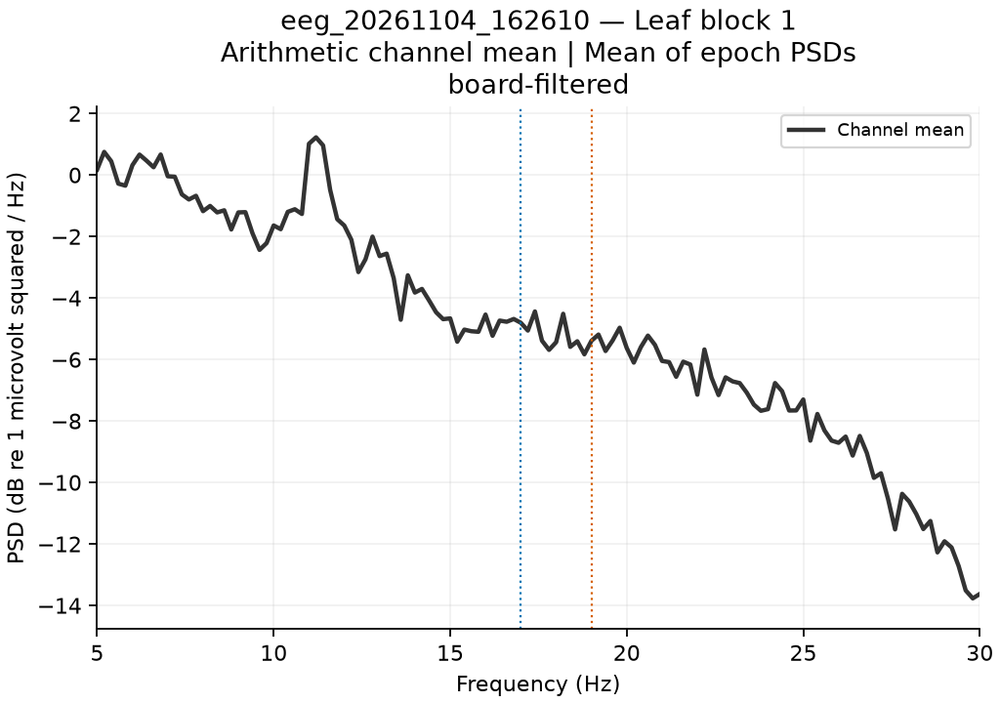
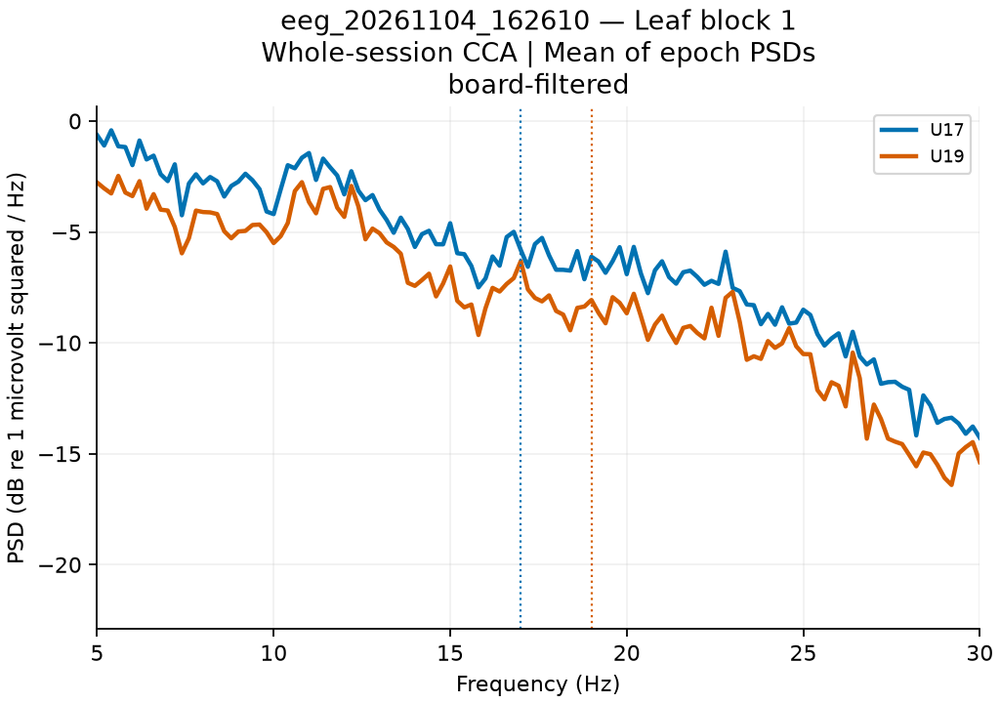
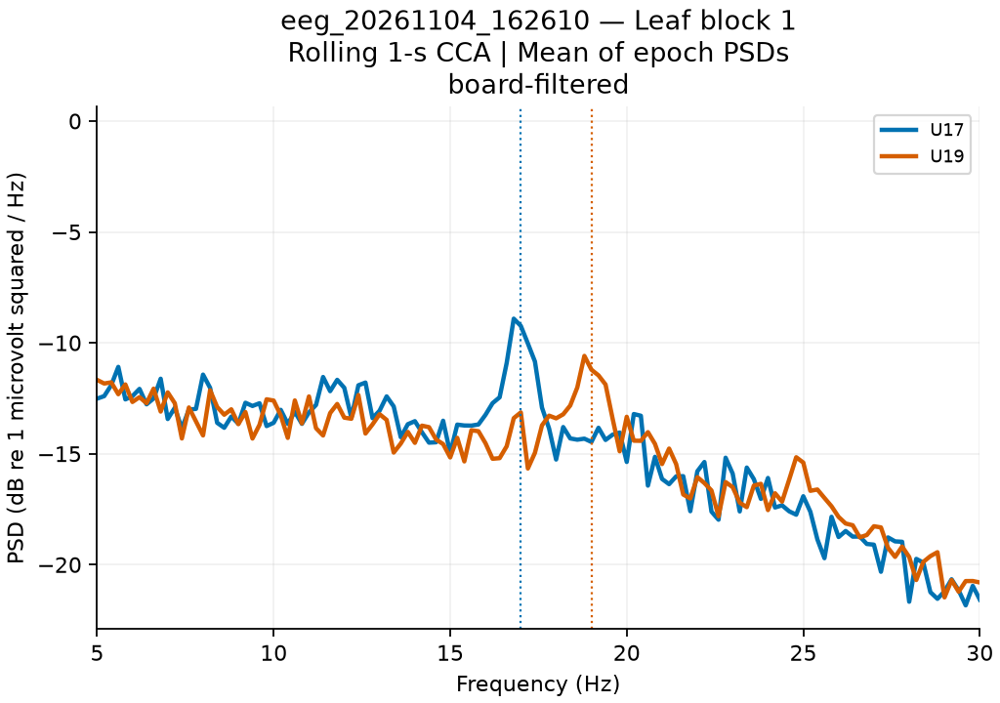
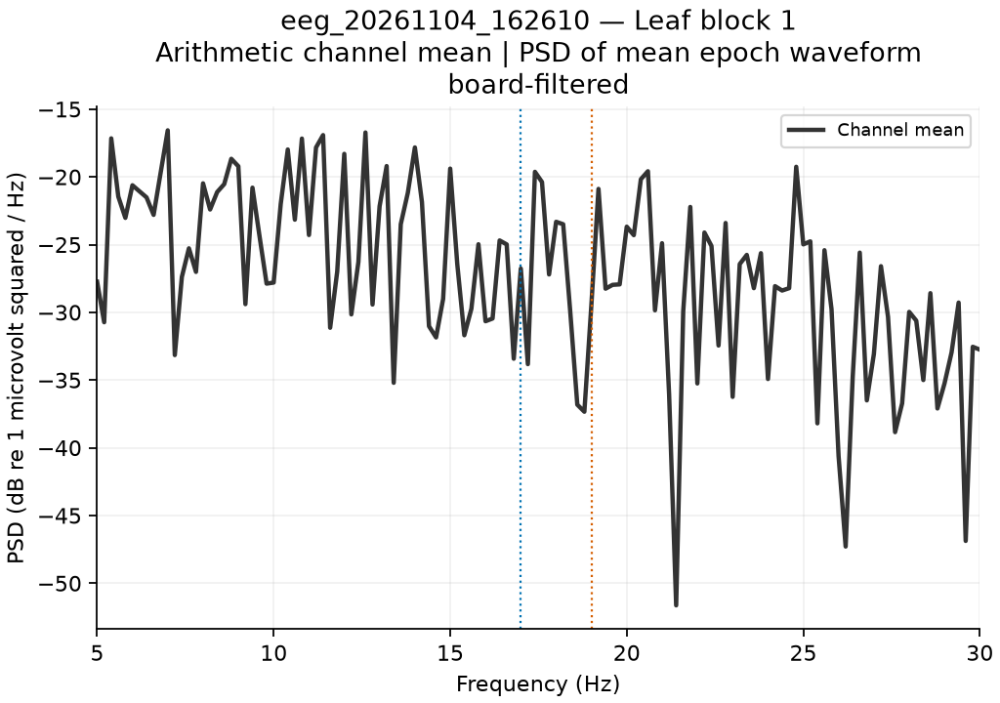
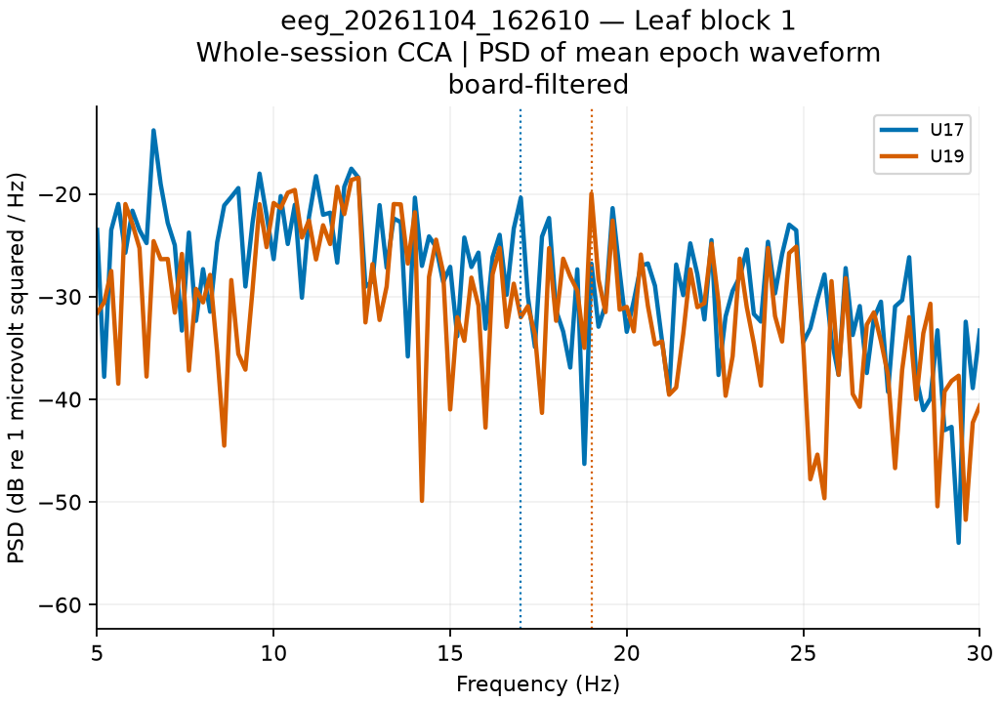
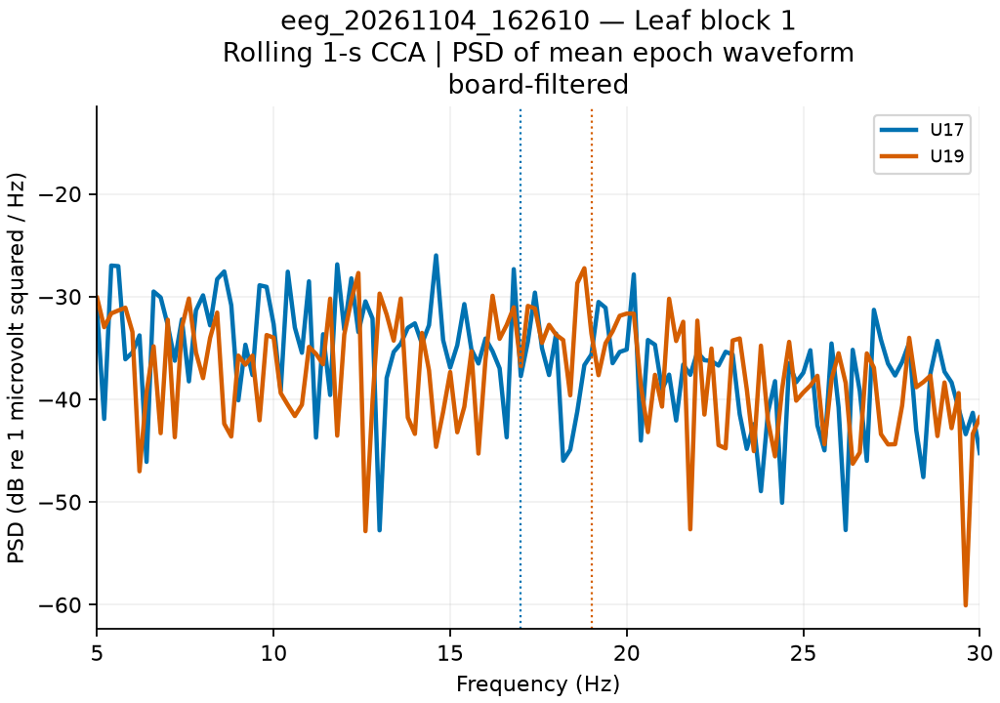

In [10]:
plot_session(records[0])

## Continuous recording: block 2

Channel mean, whole-recording CCA and rolling CCA, with both averaging orders.

Channel mean,Whole-session CCA,Rolling CCA
"board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. PSD per epoch, then equal epoch mean in linear power. 83 complete + 1 partial 5-s epochs; 104237 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. PSD per epoch, then equal epoch mean in linear power. 83 complete + 1 partial 5-s epochs; 104237 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged CCA endpoints + offline boundary endpoints. First window back-projected; offline analysis. PSD per epoch, then equal epoch mean in linear power. 83 complete + 1 partial 5-s epochs; 104237 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG"
"board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. NaN-aware mean epoch waveform, then PSD. No event alignment. 83 complete + 1 partial 5-s epochs; 104237 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. NaN-aware mean epoch waveform, then PSD. No event alignment. 83 complete + 1 partial 5-s epochs; 104237 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged CCA endpoints + offline boundary endpoints. First window back-projected; offline analysis. NaN-aware mean epoch waveform, then PSD. No event alignment. 83 complete + 1 partial 5-s epochs; 104237 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG"

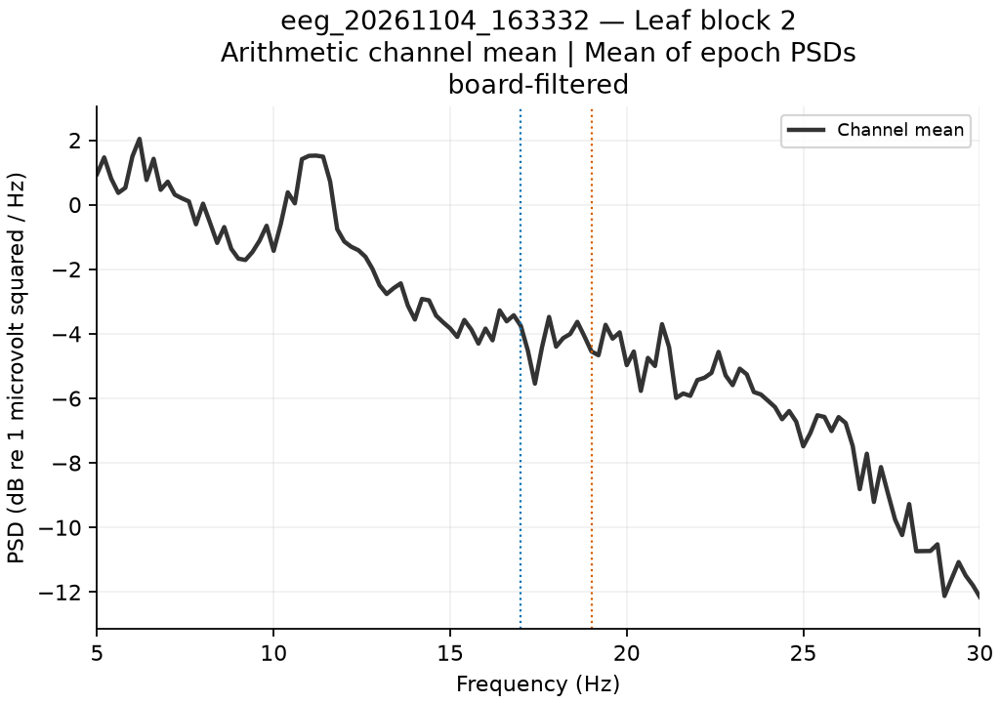
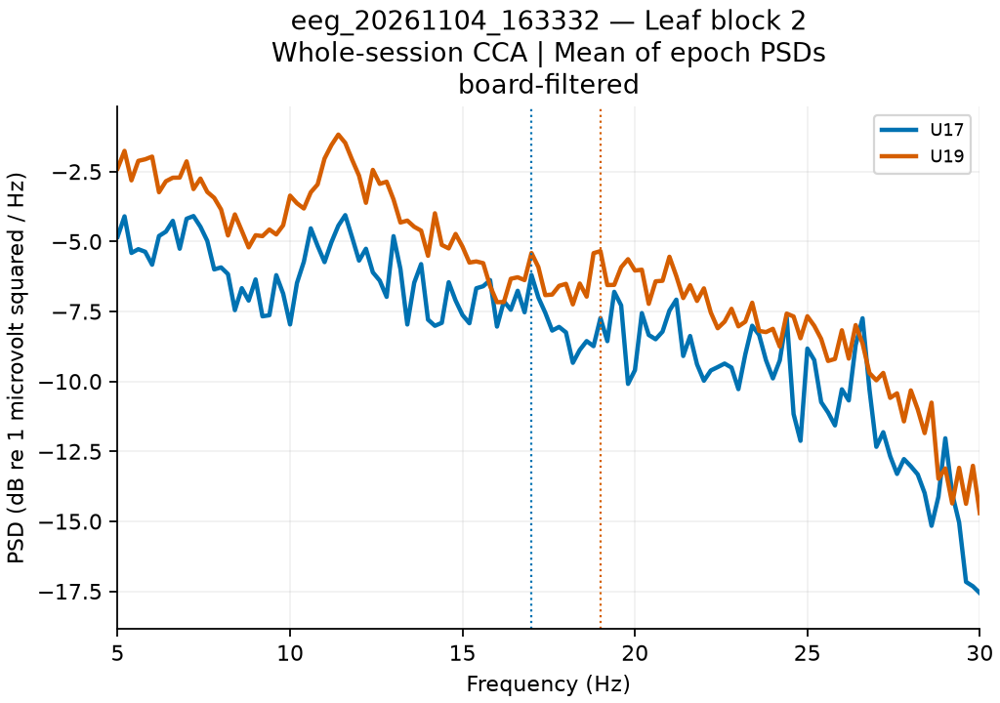
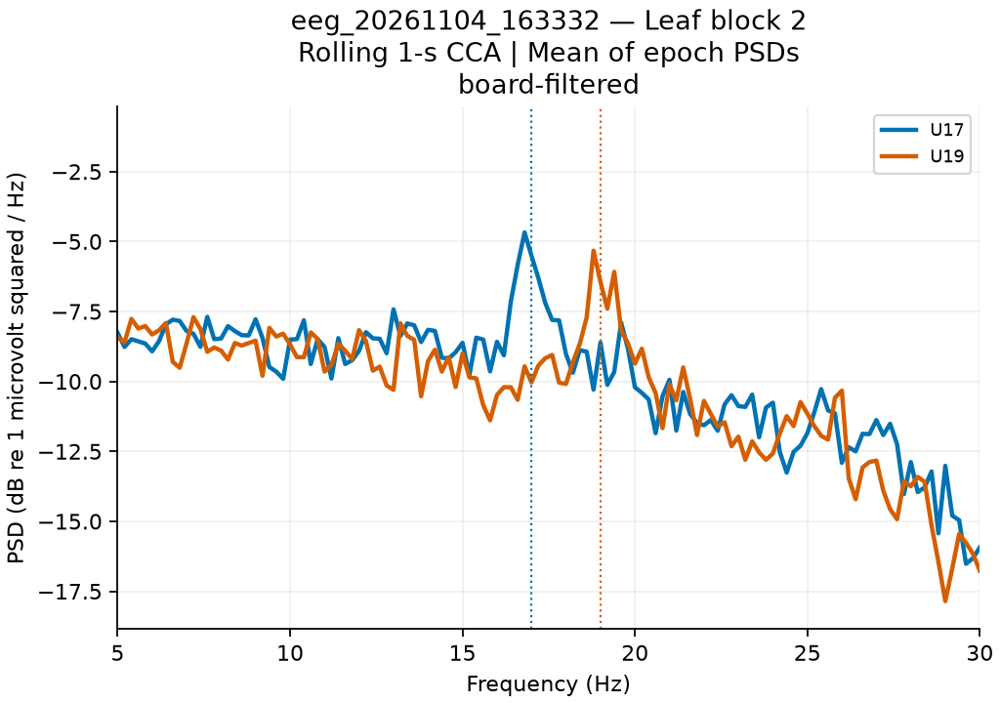
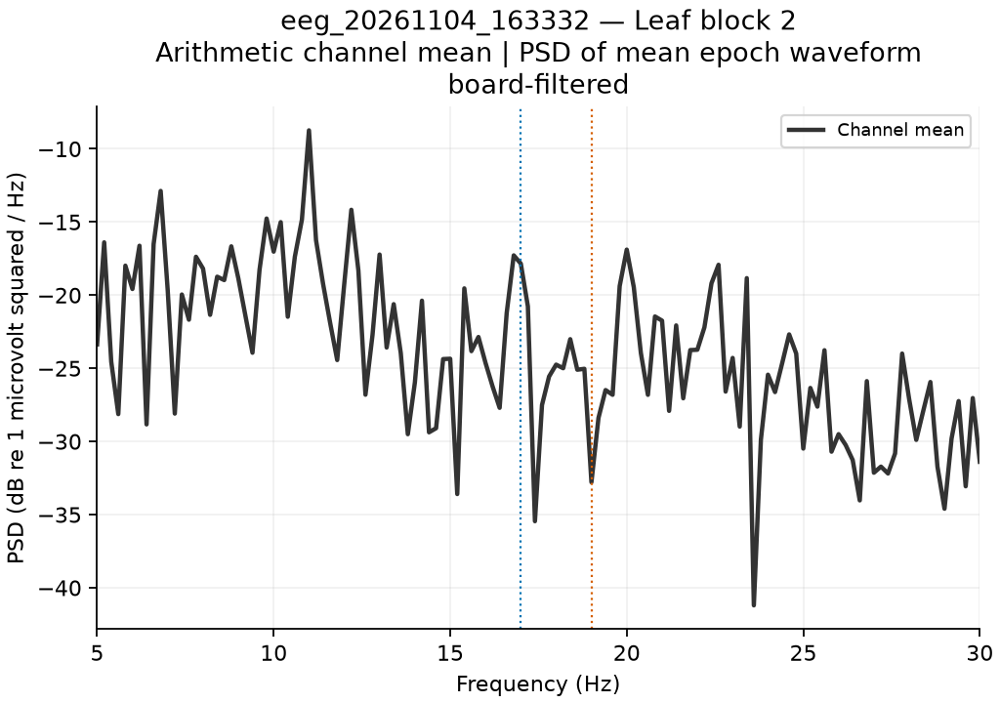
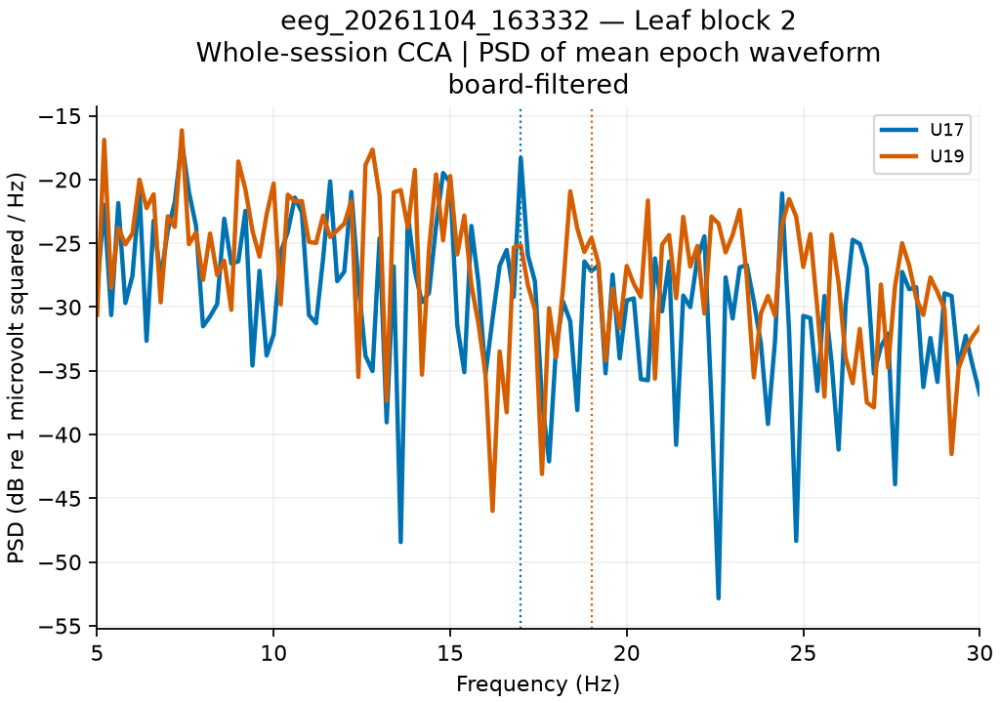
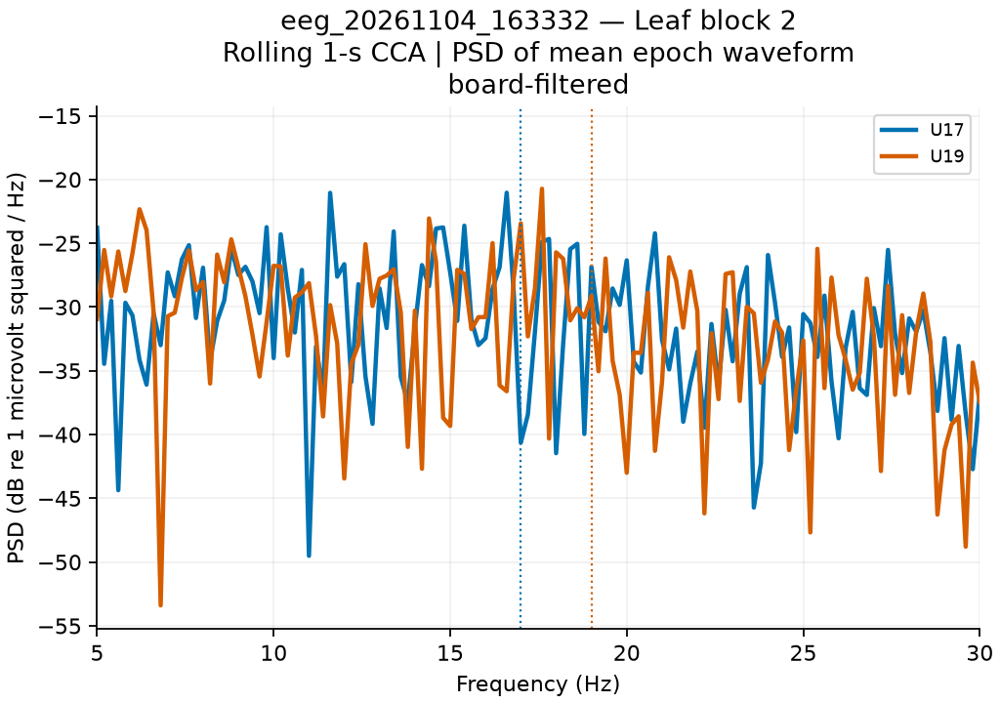

In [11]:
plot_session(records[1])

## Continuous recording: block 3

Channel mean, whole-recording CCA and rolling CCA, with both averaging orders.

Channel mean,Whole-session CCA,Rolling CCA
"board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. PSD per epoch, then equal epoch mean in linear power. 92 complete + 1 partial 5-s epochs; 116070 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. PSD per epoch, then equal epoch mean in linear power. 92 complete + 1 partial 5-s epochs; 116070 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged CCA endpoints + offline boundary endpoints. First window back-projected; offline analysis. PSD per epoch, then equal epoch mean in linear power. 92 complete + 1 partial 5-s epochs; 116070 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG"
"board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. NaN-aware mean epoch waveform, then PSD. No event alignment. 92 complete + 1 partial 5-s epochs; 116070 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. NaN-aware mean epoch waveform, then PSD. No event alignment. 92 complete + 1 partial 5-s epochs; 116070 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged CCA endpoints + offline boundary endpoints. First window back-projected; offline analysis. NaN-aware mean epoch waveform, then PSD. No event alignment. 92 complete + 1 partial 5-s epochs; 116070 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG"

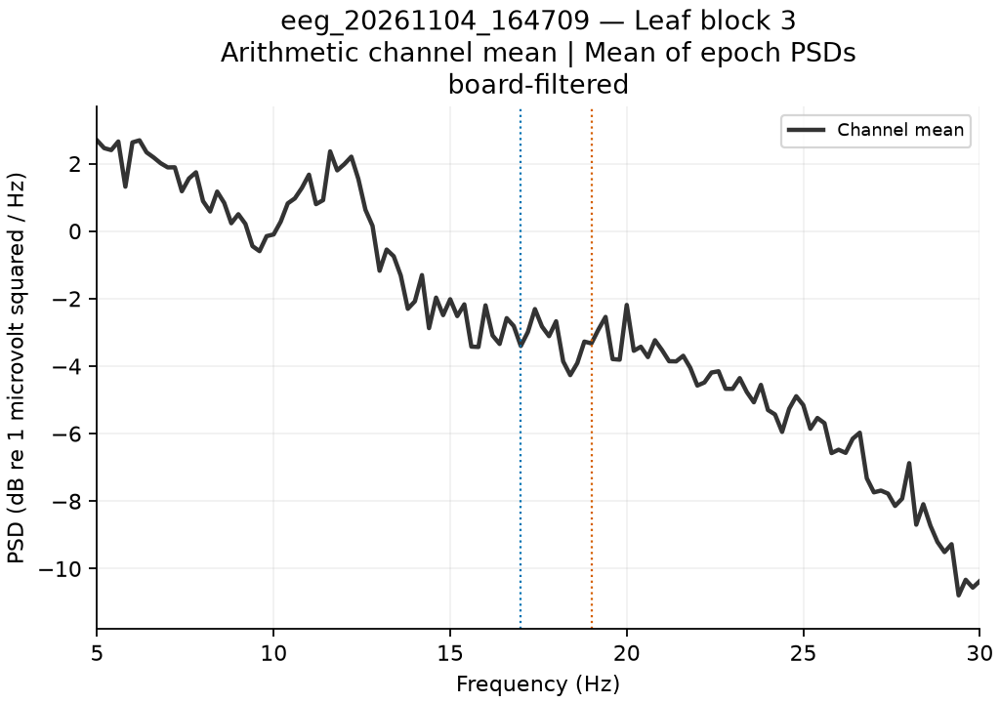
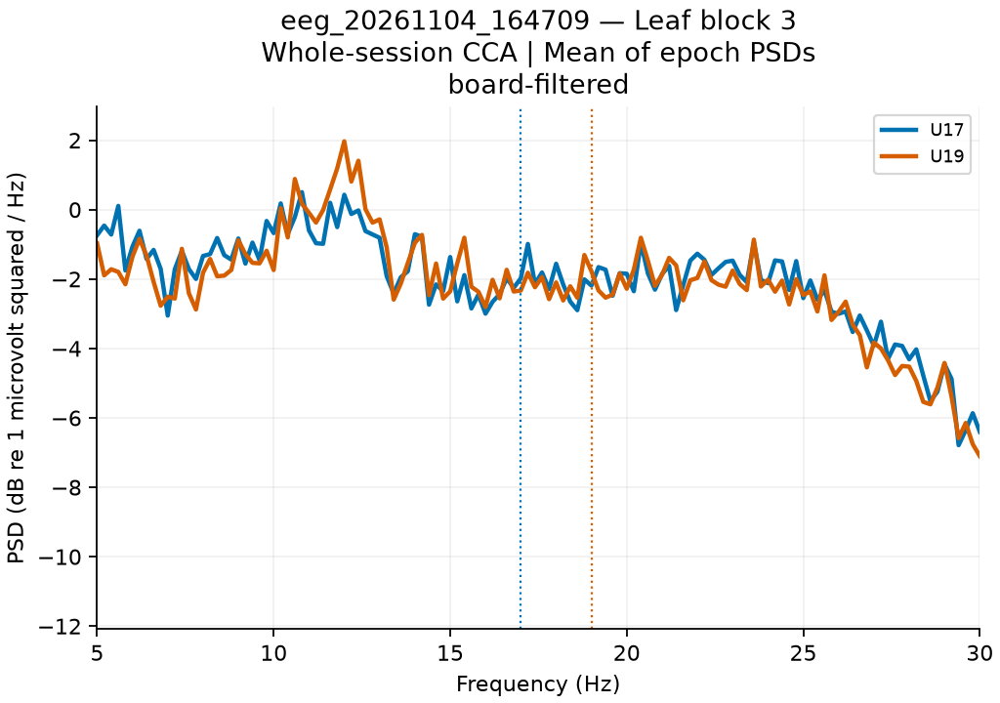
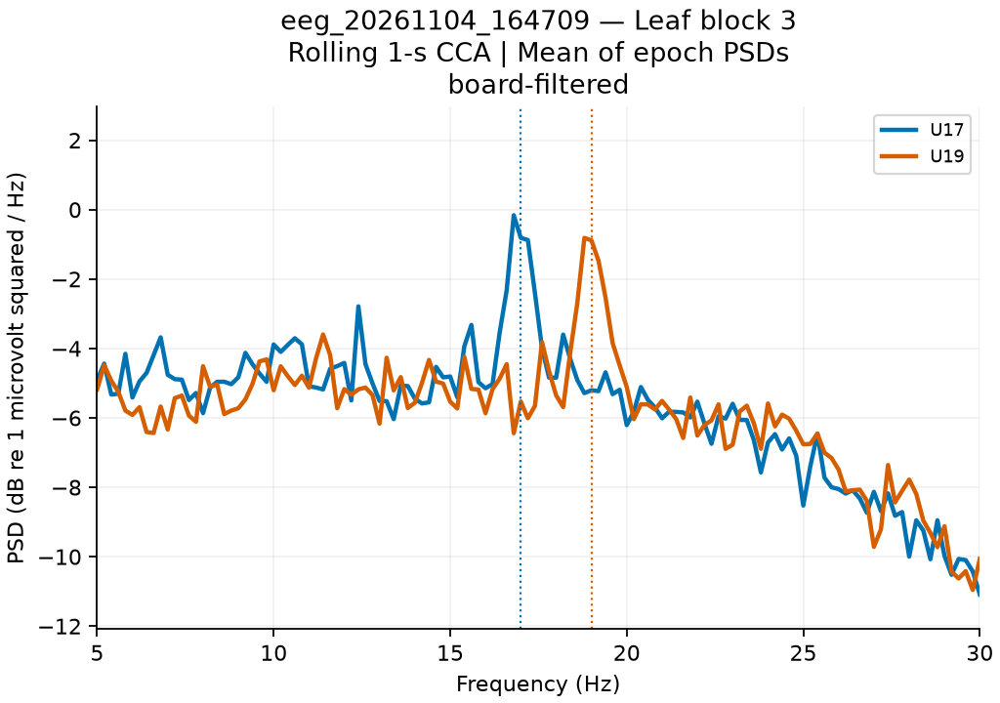
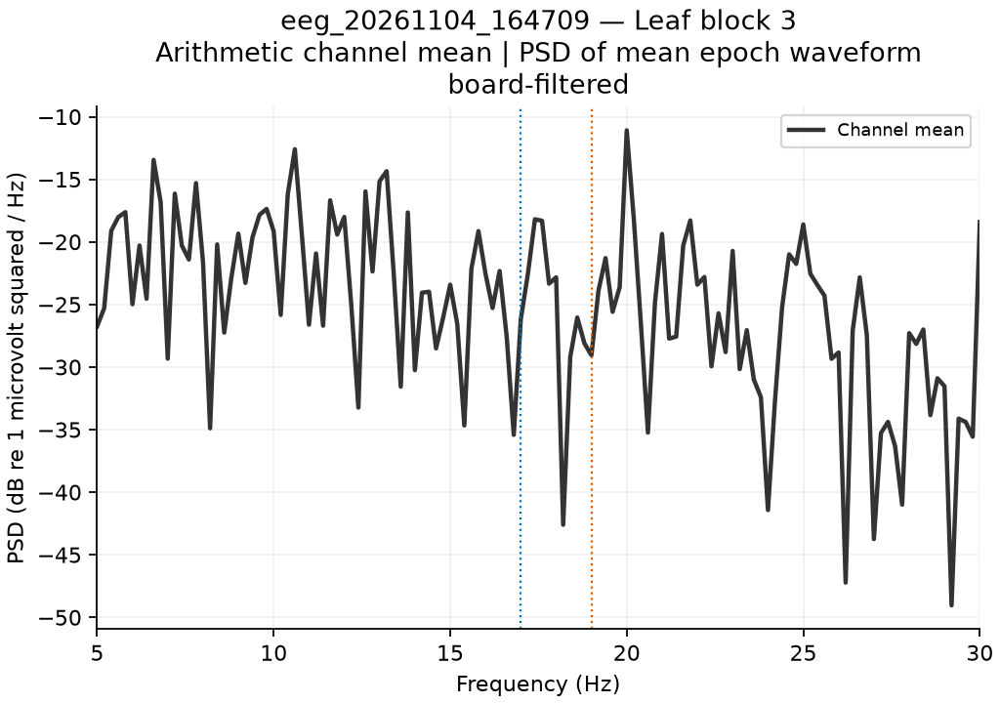
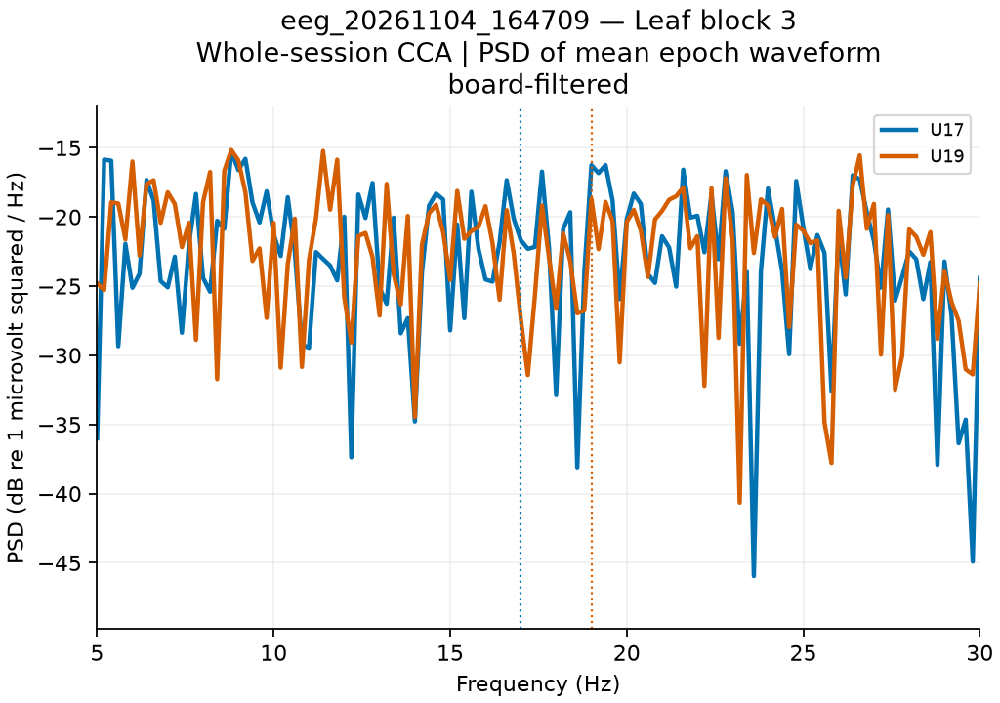
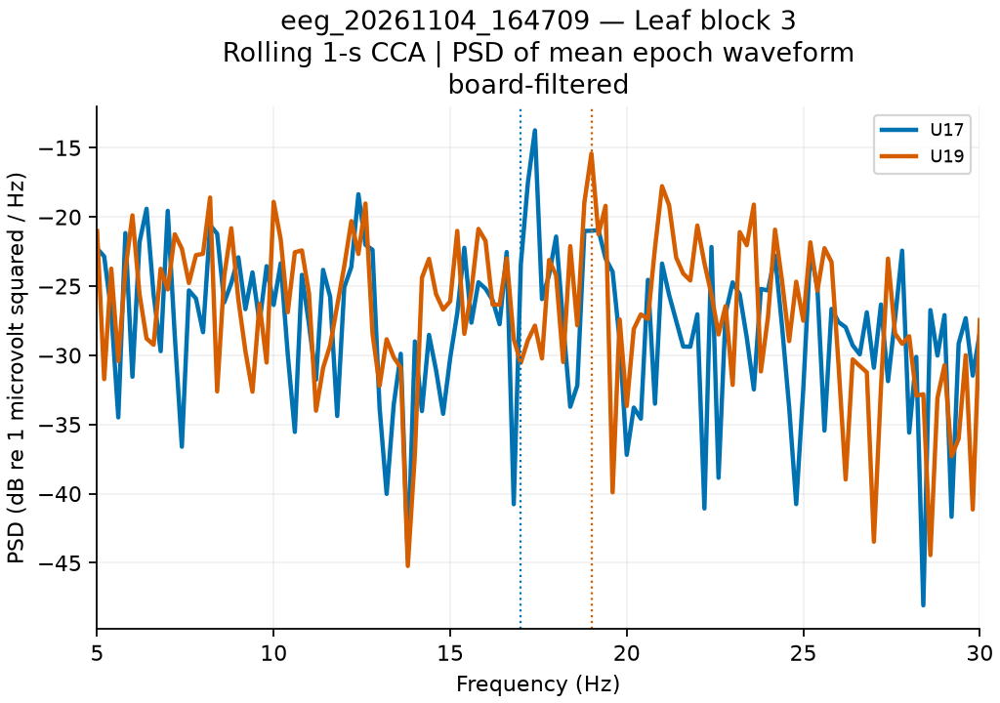

In [12]:
plot_session(records[2])

## Continuous recording: block 4

Channel mean, whole-recording CCA and rolling CCA, with both averaging orders.

Channel mean,Whole-session CCA,Rolling CCA
"board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. PSD per epoch, then equal epoch mean in linear power. 109 complete + 1 partial 5-s epochs; 136878 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. PSD per epoch, then equal epoch mean in linear power. 109 complete + 1 partial 5-s epochs; 136878 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged CCA endpoints + offline boundary endpoints. First window back-projected; offline analysis. PSD per epoch, then equal epoch mean in linear power. 109 complete + 1 partial 5-s epochs; 136878 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG"
"board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Mean of selected channels before epoching. NaN-aware mean epoch waveform, then PSD. No event alignment. 109 complete + 1 partial 5-s epochs; 136878 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Independent target weights fitted once using the whole session. NaN-aware mean epoch waveform, then PSD. No event alignment. 109 complete + 1 partial 5-s epochs; 136878 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG","board-filtered; channels: C9, C10, C11, C12, C13, C14, C15, C16. Latest 1-s windows; logged CCA endpoints + offline boundary endpoints. First window back-projected; offline analysis. NaN-aware mean epoch waveform, then PSD. No event alignment. 109 complete + 1 partial 5-s epochs; 136878 samples, all retained. DPSS NW=1/K=1; 0.2 Hz FFT grid. 17/19 Hz are logged stimulus frequencies for today.PNG | SVG"

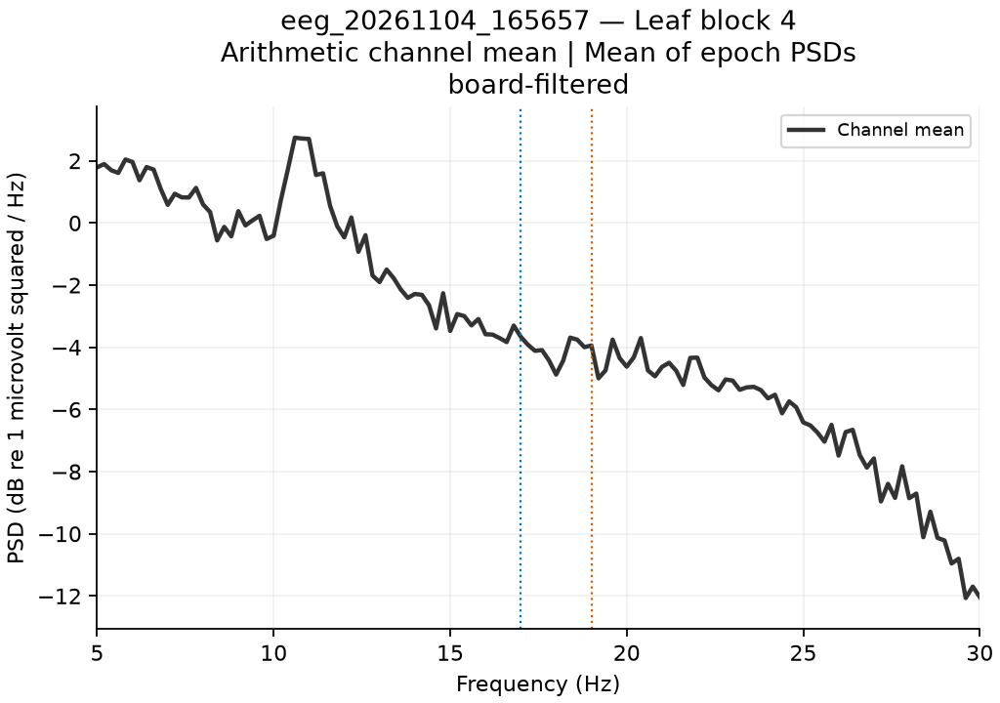
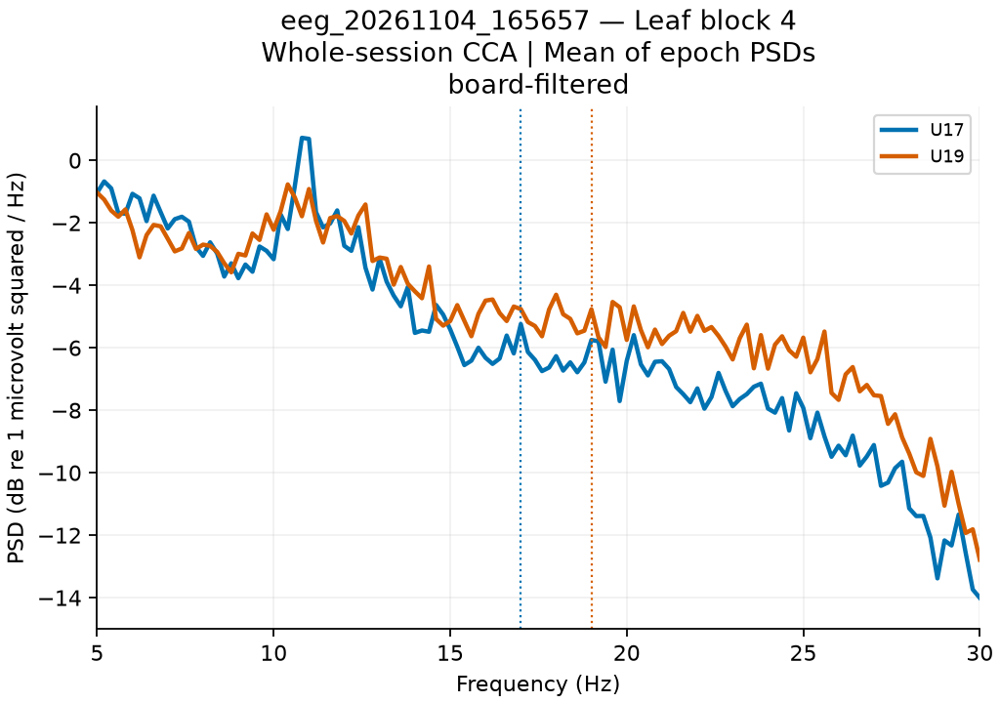
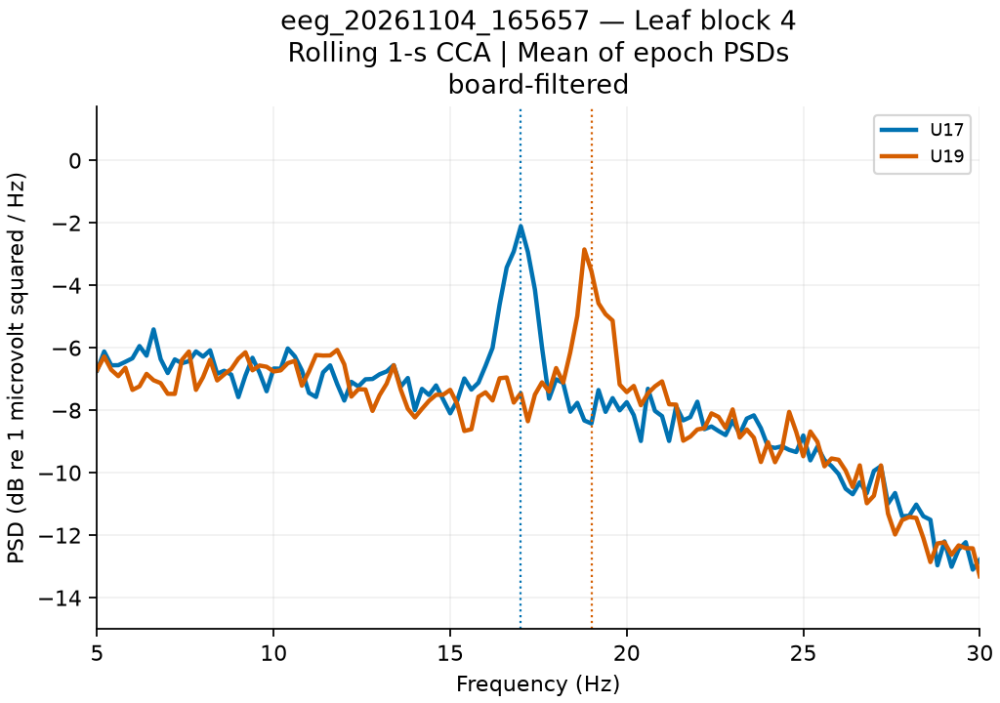
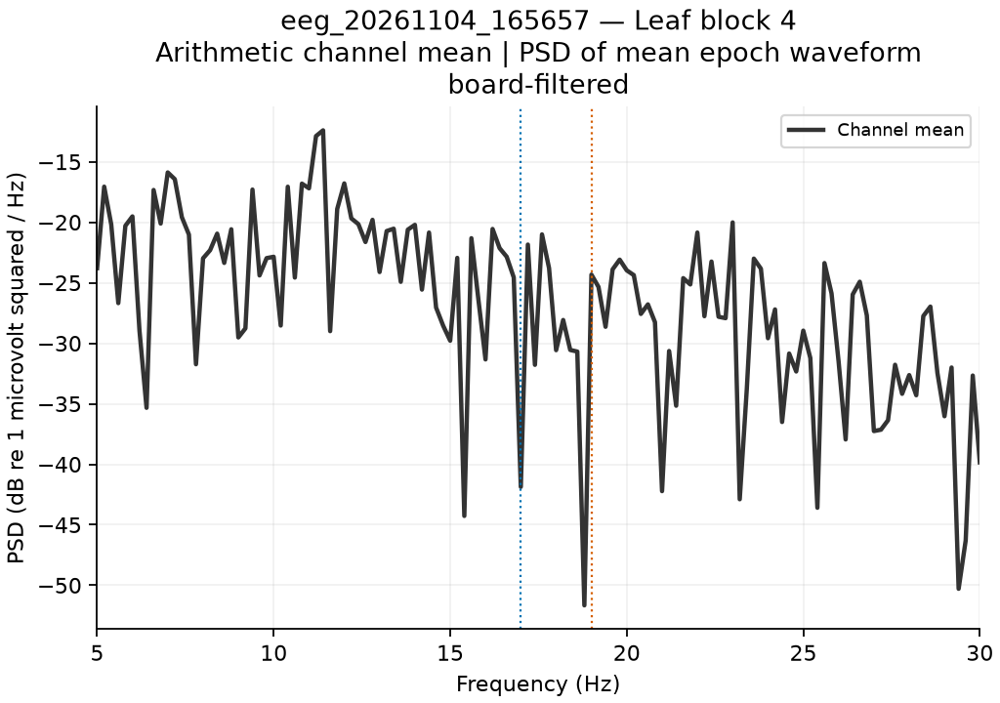
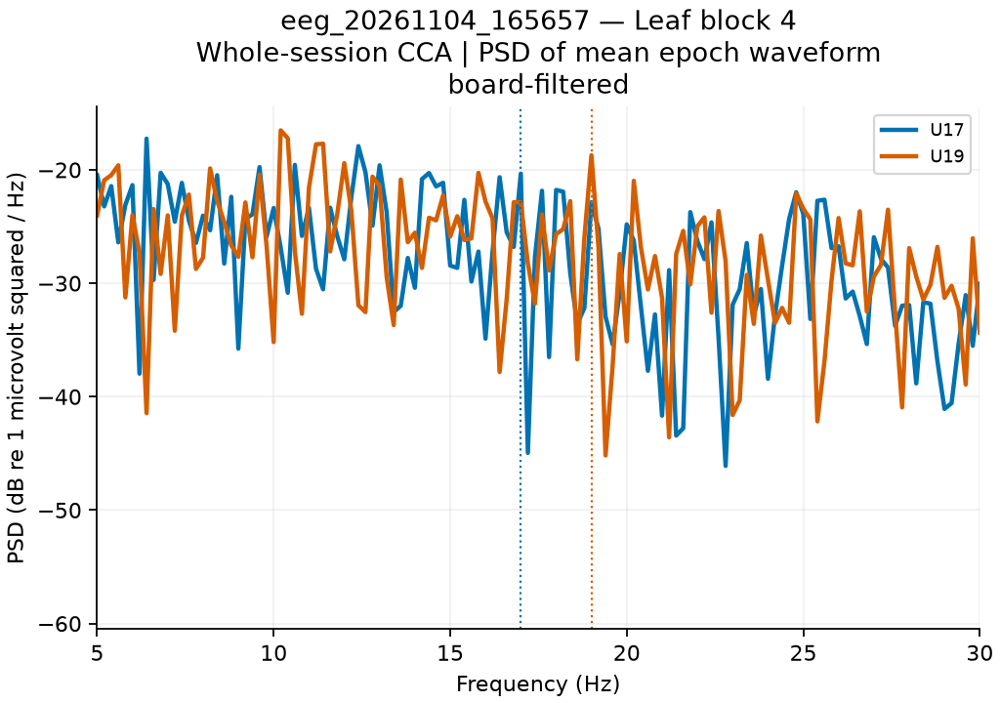
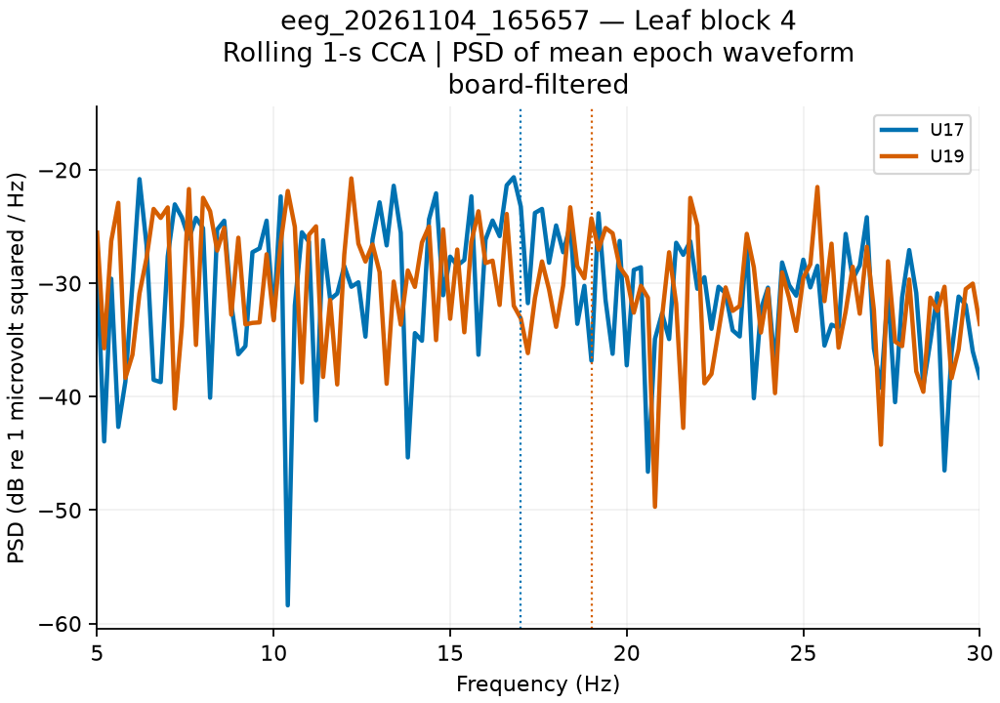

In [13]:
plot_session(records[3])

## Behavior across blocks: C1 pointing and C2 motion

All-trial accuracy includes all 12 trials per cue per block; reveal timeouts count as unsuccessful.
Response accuracy uses valid responses only. Reaction time is from color onset and includes
**correct, valid responses only**: median plus individual observations. Reveal latency includes
revealed trials only; reveal timeout rates are shown separately. These are descriptive results
without population-level error bars. Counts for every denominator are exported.


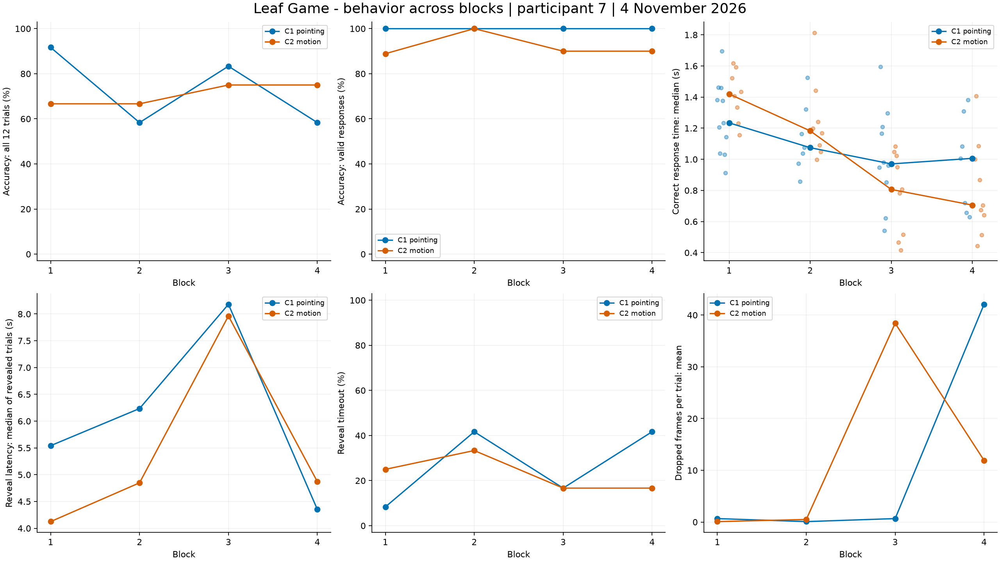


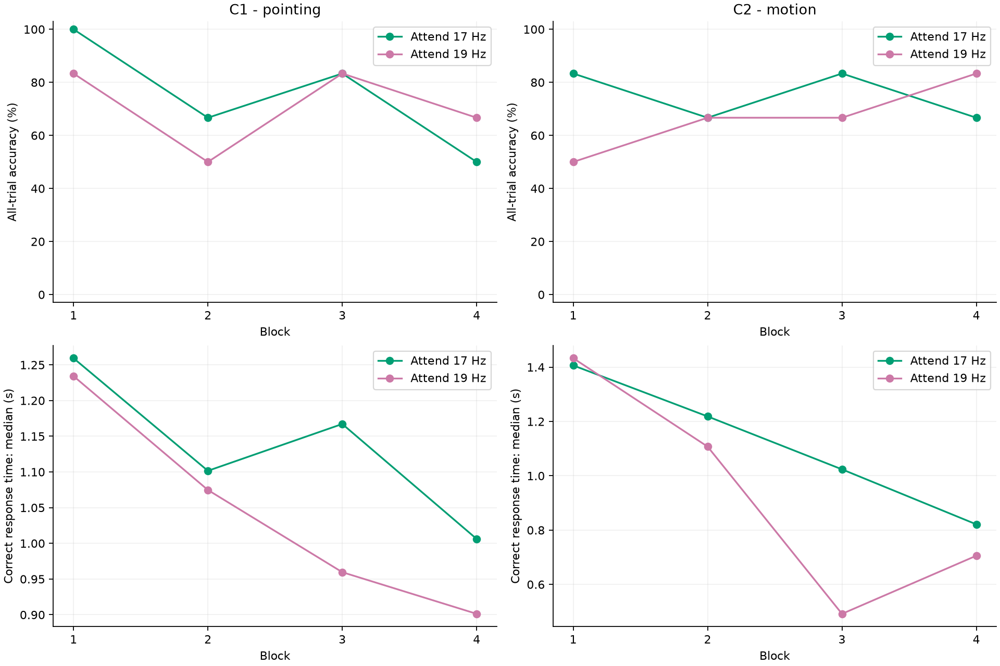

,block,Cue,n_trials,correct,valid_responses,correct_rt_n,revealed_n,accuracy_percent,response_accuracy_percent,median_correct_rt_seconds,mean_correct_rt_seconds,median_reveal_wait_seconds,reveal_timeout_percent,response_timeout_percent,mean_dropped_frames
0,1,c1,12,11,11,11,11,91.666667,100.000000,1.234223,1.267266,5.541831,8.333333,0.0,0.666667
1,1,c2,12,8,9,8,9,66.666667,88.888889,1.419837,1.411495,4.124683,25.000000,0.0,0.083333
2,2,c1,12,7,7,7,7,58.333333,100.000000,1.074733,1.136293,6.234828,41.666667,0.0,0.083333
3,2,c2,12,8,8,8,8,66.666667,100.000000,1.182803,1.249353,4.848380,33.333333,0.0,0.500000
4,3,c1,12,10,10,10,10,83.333333,100.000000,0.970399,1.017250,8.180432,16.666667,0.0,0.666667
5,3,c2,12,9,10,9,10,75.000000,90.000000,0.806359,0.788203,7.962223,16.666667,0.0,38.416667
6,4,c1,12,7,7,7,7,58.333333,100.000000,1.006169,0.969252,4.352195,41.666667,0.0,42.083333
7,4,c2,12,9,10,9,10,75.000000,90.000000,0.705727,0.815267,4.870782,16.666667,0.0,11.916667


In [14]:
def behavior_summary(table,keys):
 rows=[]
 for key,g in table.groupby(keys,sort=True):
  if not isinstance(key,tuple):key=(key,)
  valid=g[g.valid_response];correct=valid[valid.Accuracy.eq(1)]
  revealed=g[g.RevealTimeout.eq(0)&g.reveal_wait_seconds.ge(0)]
  row=dict(zip(keys,key));row.update(n_trials=len(g),correct=int(g.Accuracy.sum()),valid_responses=len(valid),correct_rt_n=len(correct),revealed_n=len(revealed),accuracy_percent=100*g.Accuracy.mean(),response_accuracy_percent=100*valid.Accuracy.mean() if len(valid) else np.nan,median_correct_rt_seconds=correct.ReactionTime.median(),mean_correct_rt_seconds=correct.ReactionTime.mean(),median_reveal_wait_seconds=revealed.reveal_wait_seconds.median(),reveal_timeout_percent=100*g.RevealTimeout.mean(),response_timeout_percent=100*g.ResponseTimeout.mean(),mean_dropped_frames=g.DroppedFrameCount.mean())
  rows.append(row)
 return pd.DataFrame(rows)
behavior_by_block=behavior_summary(behavior,['block','Cue'])
behavior_by_frequency=behavior_summary(behavior,['block','Cue','attended_hz'])
behavior.to_csv(EXPORT_ROOT/'behavior_trials.csv',index=False)
behavior_by_block.to_csv(EXPORT_ROOT/'behavior_by_block_condition.csv',index=False)
behavior_by_frequency.to_csv(EXPORT_ROOT/'behavior_by_block_condition_frequency.csv',index=False)
extra_exports=[]
def save_extra(fig,stem,title,caption):
 png=EXPORT_ROOT/f'{stem}.png';svg=EXPORT_ROOT/f'{stem}.svg'
 fig.savefig(png,dpi=PLOT_EXPORT_DPI);fig.savefig(svg);plt.close(fig)
 extra_exports.append(dict(png=png.name,svg=svg.name,title=title,caption=caption))
 display(HTML(f'<h3>{html.escape(title)}</h3><img src="data:image/png;base64,{base64.b64encode(png.read_bytes()).decode()}" style="width:100%"><p>{html.escape(caption)}</p>'))
colors={'c1':'#0072B2','c2':'#D55E00'}
metrics=[('accuracy_percent','Accuracy: all 12 trials (%)'),('response_accuracy_percent','Accuracy: valid responses (%)'),('median_correct_rt_seconds','Correct response time: median (s)'),('median_reveal_wait_seconds','Reveal latency: median of revealed trials (s)'),('reveal_timeout_percent','Reveal timeout (%)'),('mean_dropped_frames','Dropped frames per trial: mean')]
fig,axes=plt.subplots(2,3,figsize=(16,9),constrained_layout=True)
for ax,(metric,label) in zip(axes.flat,metrics):
 for cue in ['c1','c2']:
  g=behavior_by_block[behavior_by_block.Cue.eq(cue)]
  ax.plot(g.block,g[metric],'-o',color=colors[cue],label=f'{cue.upper()} '+('pointing' if cue=='c1' else 'motion'))
  if metric=='median_correct_rt_seconds':
   for b in range(1,5):
    rr=behavior[behavior.block.eq(b)&behavior.Cue.eq(cue)&behavior.valid_response&behavior.Accuracy.eq(1)]
    jitter=np.linspace(-.055,.055,len(rr))+(-.09 if cue=='c1' else .09)
    ax.scatter(b+jitter,rr.ReactionTime,s=18,color=colors[cue],alpha=.4)
 ax.set(xlabel='Block',ylabel=label,xticks=[1,2,3,4]);ax.legend(fontsize=8)
 if metric.endswith('percent'):ax.set_ylim(-3,103)
fig.suptitle('Leaf Game - behavior across blocks | participant 7 | 4 November 2026',fontsize=16)
save_extra(fig,'behavior_across_blocks_c1_c2','Behavior across blocks: C1 and C2','All-trial accuracy includes reveal timeouts. Correct RT: median plus observations. Reveal latency excludes timeouts. n=12 trials per cue per block; all denominators exported.')
fig,axes=plt.subplots(2,2,figsize=(12,8),constrained_layout=True)
for col,cue in enumerate(['c1','c2']):
 for hz,color in [(17.,'#009E73'),(19.,'#CC79A7')]:
  g=behavior_by_frequency[behavior_by_frequency.Cue.eq(cue)&behavior_by_frequency.attended_hz.eq(hz)]
  axes[0,col].plot(g.block,g.accuracy_percent,'-o',color=color,label=f'Attend {hz:g} Hz')
  axes[1,col].plot(g.block,g.median_correct_rt_seconds,'-o',color=color,label=f'Attend {hz:g} Hz')
 axes[0,col].set(title=f'{cue.upper()} - '+('pointing' if cue=='c1' else 'motion'),ylabel='All-trial accuracy (%)',ylim=(-3,103))
 axes[1,col].set(ylabel='Correct response time: median (s)')
for ax in axes.flat:ax.set(xlabel='Block',xticks=[1,2,3,4]);ax.legend()
save_extra(fig,'behavior_by_attended_frequency','Behavior split by attended frequency','Six trials per cue x attended-frequency cell in each block. RT includes correct valid responses only. Counts are exported.')
display(behavior_by_block)

## Trial intervals and clock checks

Each trial starts on its own 31-34 EEG event. The analysis interval ends immediately before
50 (color onset), or 30 (stop) for a reveal timeout. Stops and responses must match behavioral
outcomes. The fitted game/EEG clock relationship is an audit only; actual sample indices
cut every trial. Software-trigger reception leaves display/transport latency unresolved.

In [15]:
trial_rows=[];trial_waves=[];clock_rows=[]
for rec in records:
 events=rec['events'];trials=rec['behavior'];seq=rec['seq']
 slope,intercept=np.polyfit(trials.TrialStart,(trials.start_seq-seq[0])/FS,1)
 residual=(trials.start_seq-seq[0])/FS-(intercept+slope*trials.TrialStart)
 clock_rows.append(dict(block=rec['block'],eeg_seconds_per_game_second=slope,intercept_seconds=intercept,max_abs_start_residual_seconds=float(np.max(np.abs(residual)))))
 for k,row in enumerate(trials.itertuples()):
  lo=int(row.start_pos);next_start=int(trials.start_pos.iloc[k+1]) if k+1<len(trials) else len(seq)
  ev=events[(events.position>lo)&(events.position<next_start)]
  stops=ev[ev.marker.eq(30)];reveals=ev[ev.marker.eq(50)];responses=ev[ev.marker.eq(40)]
  assert len(stops)==1 and len(reveals)==int(row.RevealTimeout==0) and len(responses)==int(row.valid_response)
  stop=int(stops.position.iloc[0]);hi=int(reveals.position.iloc[0]) if len(reveals) else stop
  assert lo<hi<=stop and hi-lo>=WINDOW_SAMPLES
  if len(responses):assert hi<int(responses.position.iloc[0])<stop
  info=dict(block=rec['block'],session=rec['session'],trial=row.TrialNumber,cue=row.Cue,attended_hz=row.attended_hz,distractor_hz=row.distractor_hz,start_marker=row.TrialStartMarker,first_seq=int(seq[lo]),end_exclusive_seq=int(seq[hi]),stop_seq=int(seq[stop]),observed_samples=hi-lo,analysis_seconds=(hi-lo)/FS,reveal_timeout=int(row.RevealTimeout),end_reason='reveal_timeout_stop' if row.RevealTimeout else 'color_onset')
  trial_rows.append(info);trial_waves.append(dict(info=info,rec=rec,lo=lo,hi=hi))
trial_audit=pd.DataFrame(trial_rows);clock_audit=pd.DataFrame(clock_rows)
trial_audit.to_csv(EXPORT_ROOT/'trial_interval_audit.csv',index=False)
clock_audit.to_csv(EXPORT_ROOT/'game_eeg_clock_audit.csv',index=False)
display(clock_audit)
display(trial_audit.groupby(['block','cue','attended_hz']).agg(trials=('trial','size'),samples=('observed_samples','sum'),mean_seconds=('analysis_seconds','mean')))

,block,eeg_seconds_per_game_second,intercept_seconds,max_abs_start_residual_seconds
0,1,0.998561,61.659528,0.004470
1,2,0.998549,22.946512,0.017195
2,3,0.998518,76.946164,0.050143
3,4,0.998534,189.686368,0.013352


trials  samples  mean_seconds
block cue attended_hz                               
1     c1  17.0              6     9134      6.089333
          19.0              6    14134      9.422667
      c2  17.0              6     7812      5.208000
          19.0              6    17805     11.870000
2     c1  17.0              6    14565      9.710000
          19.0              6    16132     10.754667
      c2  17.0              6    15321     10.214000
          19.0              6    13085      8.723333
3     c1  17.0              6    14251      9.500667
          19.0              6    13108      8.738667
      c2  17.0              6    14935      9.956667
          19.0              6    14335      9.556667
4     c1  17.0              6    14155      9.436667
          19.0              6    13623      9.082000
      c2  17.0              6     9416      6.277333
          19.0              6    13135      8.756667

## C1/C2 spectra by block and attended frequency

CCA is fitted independently at 17 and 19 Hz inside each trial's entire pre-color interval.
Rolling fits reset at trial onset, using logged endpoints inside the interval plus its first
complete 1-second window and final sample. Fits never cross a trial boundary.

Average epoch PSDs within each trial first, then average six trials equally per cue x frequency
cell. Waveform-first views similarly average epochs within trial, then trials equally;
these are descriptive waveform averages, not evoked responses. All partial tails are retained.
Rows separate attend 17 Hz and attend 19 Hz; columns compare channel mean, whole-trial CCA
and rolling CCA. Solid CCA line = attended projection; dashed = distractor projection.
Both frequencies are physically present throughout each trial.

In [16]:
trial_fit_rows=[];trial_epoch_rows=[]
for item in trial_waves:
 rec,lo,hi=item['rec'],item['lo'],item['hi'];info=item['info']
 x=rec['x'][lo:hi];seq=rec['seq'][lo:hi];t=(seq-seq[0])/FS;n=len(x)
 fixed=[fit_target_cca(x,t,hz) for hz in TARGETS_HZ]
 fixed_u=np.column_stack([fit['u'] for fit in fixed])
 endpoints={int(s-seq[0]):'logged' for s in rec['nfseq'] if seq[0]+WINDOW_SAMPLES-1<=s<=seq[-1]}
 endpoints.setdefault(WINDOW_SAMPLES-1,'first_boundary');endpoints.setdefault(n-1,'last_boundary')
 rolling=np.full_like(fixed_u,np.nan);cursor=0
 def fit_row(fit,hz,method,a,b,aa,bb,origin):
  row={**info,'method':method,'target_hz':hz,'endpoint_source':origin,'fit_first_seq':int(seq[a]),'fit_last_seq':int(seq[b-1]),'assigned_first_seq':int(seq[aa]),'assigned_last_seq':int(seq[bb-1]),'rho':fit['rho']}
  row.update({f'weight_{c}':float(w) for c,w in zip(CHANNEL_NAMES,fit['w'])})
  row.update({f'mean_{c}_uv':float(v) for c,v in zip(CHANNEL_NAMES,fit['x_mean'])})
  trial_fit_rows.append(row)
 for pos,origin in sorted(endpoints.items()):
  a,b=pos-WINDOW_SAMPLES+1,pos+1
  assert cursor>=a and b>cursor
  fits=[fit_target_cca(x[a:b],t[a:b],hz) for hz in TARGETS_HZ]
  rolling[cursor:b]=np.column_stack([(x[cursor:b]-fit['x_mean'])@fit['w'] for fit in fits])
  for hz,fit in zip(TARGETS_HZ,fits):fit_row(fit,hz,'rolling_trial_cca',a,b,cursor,b,origin)
  cursor=b
 assert cursor==n and np.isfinite(rolling).all()
 for hz,fit in zip(TARGETS_HZ,fixed):
  assert np.isclose(np.linalg.norm(fit['w']),1) and np.isclose(fit['rho'],fit['rho_svd'])
  fit_row(fit,hz,'whole_trial_cca',0,n,0,n,'whole_interval')
 item['waves']={'channel_mean':x.mean(axis=1),'whole_trial_cca':fixed_u,'rolling_trial_cca':rolling}
 for k,a in enumerate(range(0,n,EPOCH_SAMPLES)):
  observed=min(EPOCH_SAMPLES,n-a)
  trial_epoch_rows.append({**info,'epoch':k+1,'epoch_samples':observed,'tail_padding':EPOCH_SAMPLES-observed})
trial_fit_audit=pd.DataFrame(trial_fit_rows);trial_epoch_audit=pd.DataFrame(trial_epoch_rows)
trial_fit_audit.to_csv(EXPORT_ROOT/'trial_cca_fit_audit.csv',index=False)
trial_epoch_audit.to_csv(EXPORT_ROOT/'trial_epoch_audit.csv',index=False)
print('Fitted independent trial intervals:',len(trial_waves))

Fitted independent trial intervals: 96



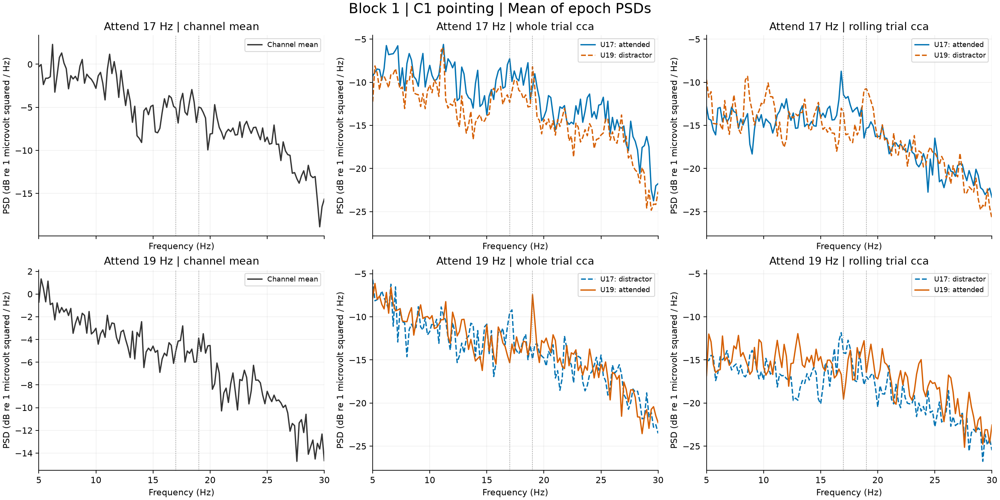


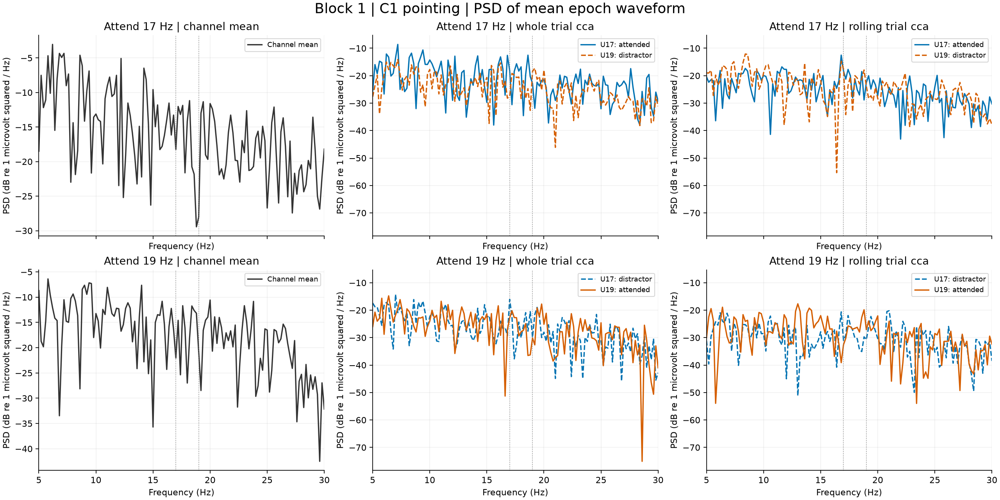


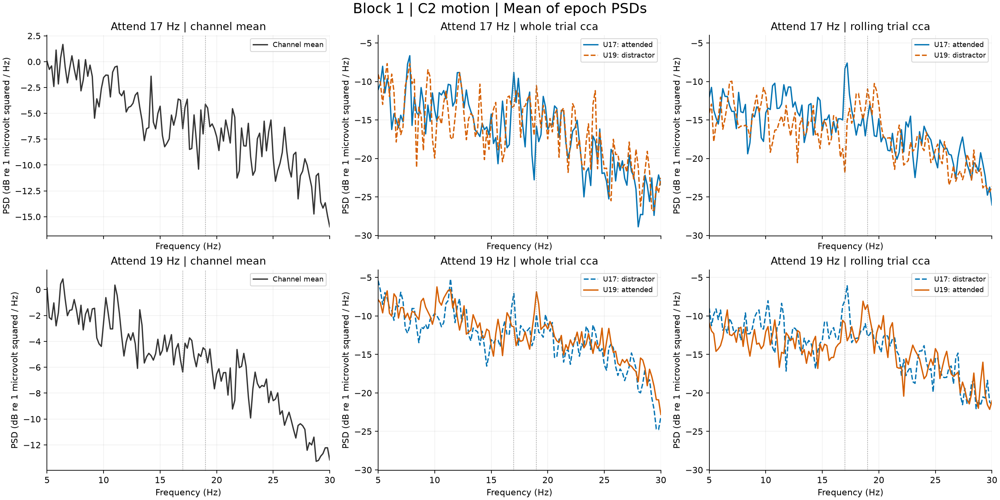


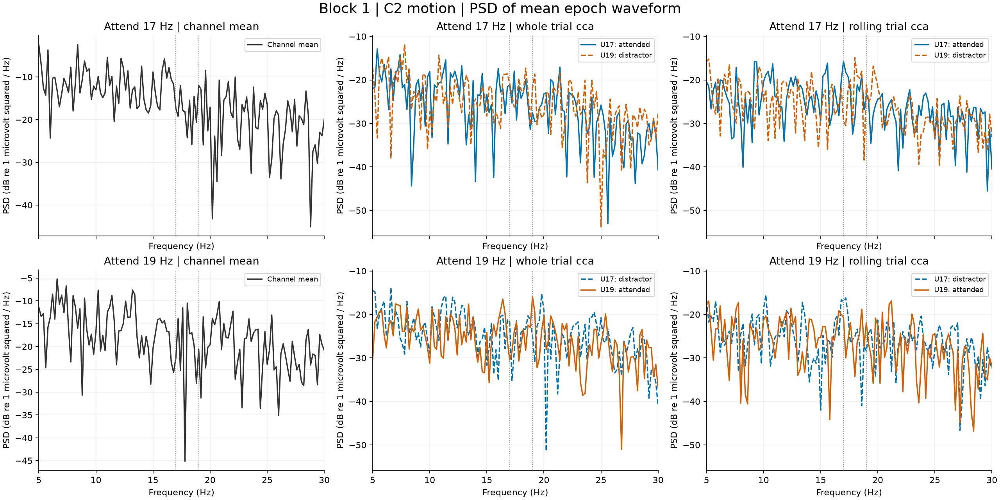


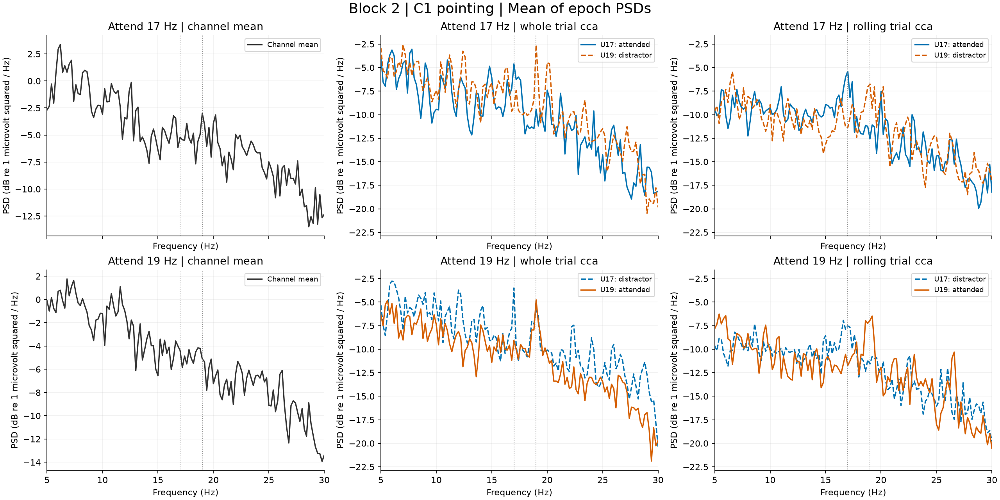


...


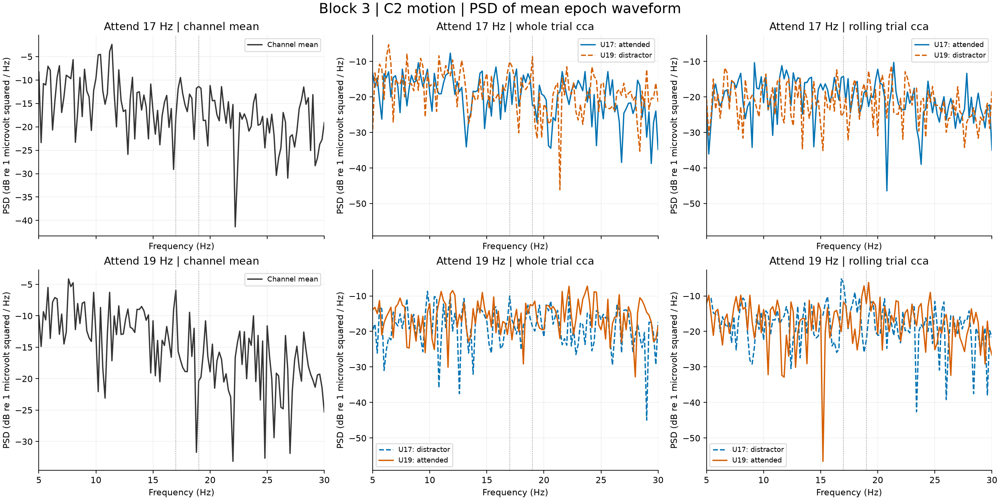


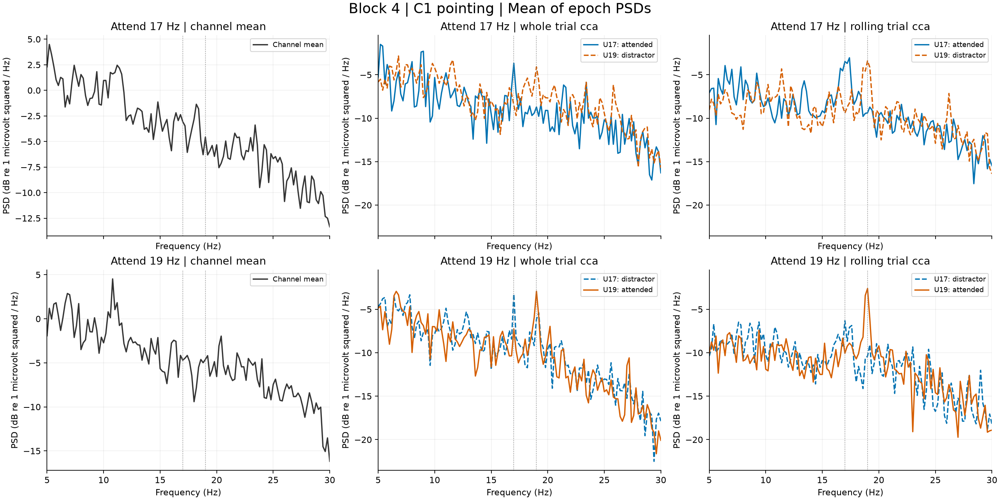


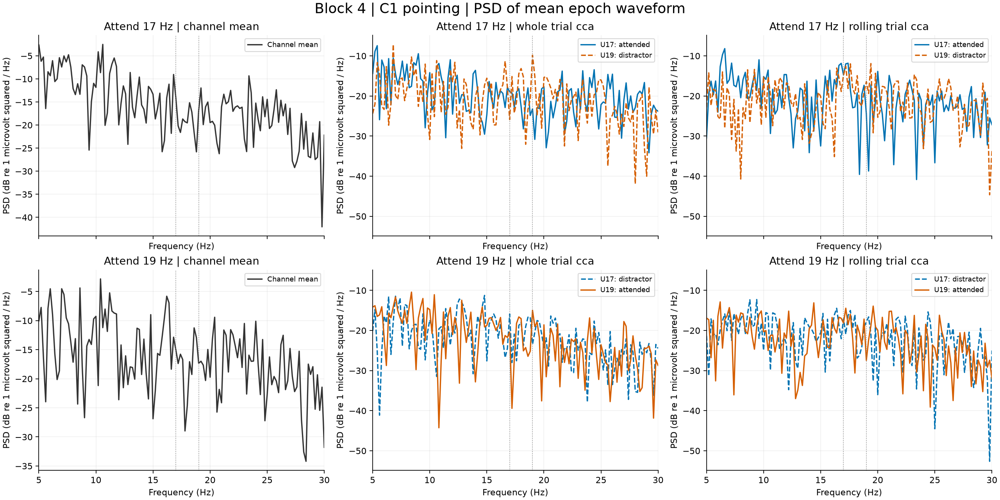


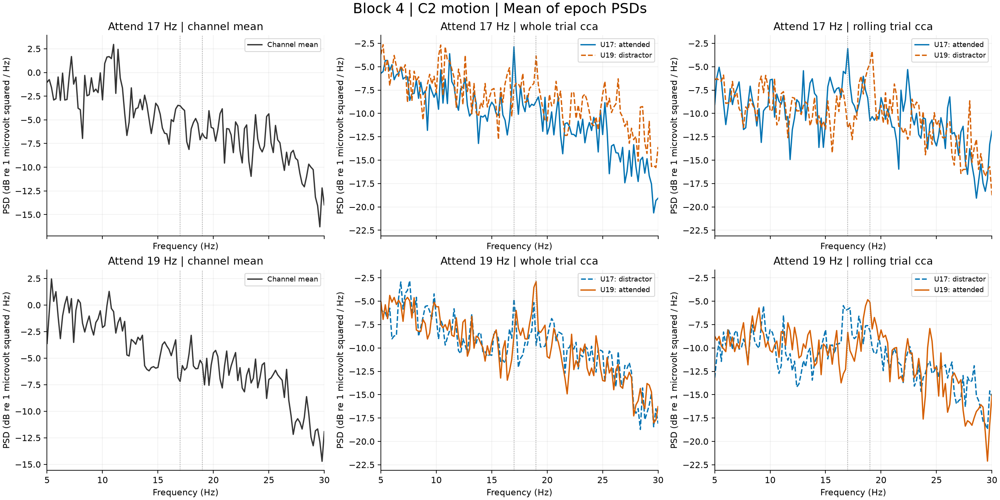


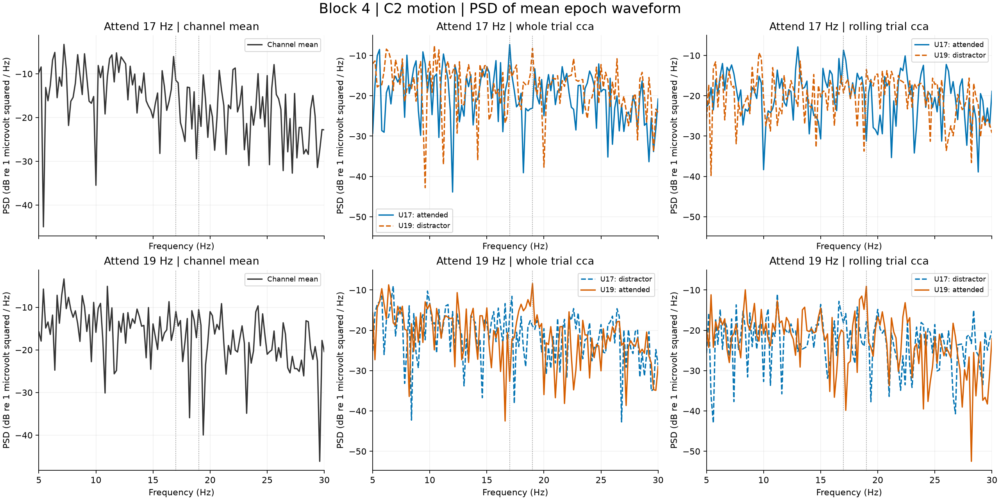

In [17]:
condition_summaries={};condition_numeric=[]
methods=['channel_mean','whole_trial_cca','rolling_trial_cca']
for block in range(1,5):
 for cue in ['c1','c2']:
  for hz in TARGETS_HZ:
   items=[w for w in trial_waves if w['info']['block']==block and w['info']['cue']==cue and w['info']['attended_hz']==hz]
   assert len(items)==6
   for method in methods:
    s=pooled_trial_spectrum_orders(epoch_trials([w['waves'][method] for w in items],EPOCH_SAMPLES),FS)
    condition_summaries[block,cue,hz,method]=s
    for order in ['induced','evoked']:
     power=s[order];power=power[:,None] if power.ndim==1 else power
     for j in range(power.shape[1]):
      condition_numeric.append(pd.DataFrame(dict(block=block,cue=cue,attended_hz=hz,method=method,order=order,component='channel_mean' if method=='channel_mean' else f'U{TARGETS_HZ[j]:g}',frequency_hz=s['f'],power_uv2_per_hz=power[:,j],n_trials=6)))
  for order in ['induced','evoked']:
   fig,axes=plt.subplots(2,3,figsize=(16,8),sharex=True,constrained_layout=True)
   cca_scale=limits_for([condition_summaries[block,cue,hz,m][order][(condition_summaries[block,cue,hz,m]['f']>=5)&(condition_summaries[block,cue,hz,m]['f']<=30)] for hz in TARGETS_HZ for m in methods[1:]])
   for row,hz in enumerate(TARGETS_HZ):
    for col,method in enumerate(methods):
     ax=axes[row,col];s=condition_summaries[block,cue,hz,method];f=s['f'];mask=(f>=5)&(f<=30)
     if method=='channel_mean':ax.plot(f[mask],db_plot(s[order][mask]),color='#333333',label='Channel mean')
     else:
      for j,target in enumerate(TARGETS_HZ):ax.plot(f[mask],db_plot(s[order][mask,j]),color='#0072B2' if target==17 else '#D55E00',ls='-' if target==hz else '--',label=f'U{target:g}: '+('attended' if target==hz else 'distractor'))
      ax.set_ylim(cca_scale)
     for target in TARGETS_HZ:ax.axvline(target,color='gray',ls=':',lw=.8)
     ax.set(title=f'Attend {hz:g} Hz | '+method.replace('_',' '),xlabel='Frequency (Hz)',ylabel='PSD (dB re 1 microvolt squared / Hz)',xlim=(5,30));ax.legend(fontsize=8)
   title=f'Block {block} | {cue.upper()} '+('pointing' if cue=='c1' else 'motion')+' | '+ORDER_TITLES[order]
   fig.suptitle(title,fontsize=16)
   save_extra(fig,f'block{block}_{cue}_condition_{order}',title,'Cue-to-color intervals; timeouts end at stop. Six trials per row, equal trial weights, 5-s epochs with partial tails. Same-data trial CCA fits. Waveform-first plots are not evoked responses.')
pd.concat(condition_numeric,ignore_index=True).to_csv(EXPORT_ROOT/'condition_spectra.csv',index=False)

## Verify coverage and export the report

Checks cover marker/frequency assignments, 96 trial intervals, exact observed-sample preservation, CCA normalization and projection recovery, matched epoch membership, and all exported figures.

In [18]:
assert len(records)==4 and len(behavior)==len(trial_audit)==96
assert behavior.groupby(['block','Cue']).size().eq(12).all()
assert behavior.groupby(['block','Cue','attended_hz']).size().eq(6).all()
assert len(plot_exports)==28 and len(extra_exports)==18
for rec in records:
 assert np.array_equal(rec['x'],rec['recorded_x'][:,SELECTED_CHANNEL_INDICES])
 assert epoch_audit.loc[epoch_audit.session.eq(rec['session']),'observed_samples'].sum()==len(rec['x'])
 assert coverage_audit.set_index('session').loc[rec['session'],'unassigned_samples']==0
 for fit in rec['fixed_fits']:
  assert np.isclose(np.linalg.norm(fit['w']),1)
  assert np.allclose(fit['u'],(rec['x']-fit['x_mean'])@fit['w'])
 for update in rec['update_fits']:
  a,b=update['lo'],update['hi']
  assert np.allclose(rec['refitted_u'][a:b],np.column_stack([(rec['x'][a:b]-fit['x_mean'])@fit['w'] for fit in update['fits']]))
 for s in rec['summaries'].values():assert np.isfinite(s['induced']).all() and np.isfinite(s['evoked']).all()
for item in trial_waves:
 info=item['info'];rr=trial_epoch_audit[(trial_epoch_audit.block==info['block'])&(trial_epoch_audit.trial==info['trial'])]
 assert rr.epoch_samples.sum()==info['observed_samples']
assert np.allclose(np.linalg.norm(trial_fit_audit[[f'weight_{c}' for c in CHANNEL_NAMES]],axis=1),1)
for s in condition_summaries.values():
 assert np.allclose(s['induced'],finite_mean(s['trial_power'],axis=0))
 assert np.allclose(s['evoked'],nan_epoch_psd(s['mean_epoch'],FS,EPOCH_SAMPLES)[1])
manifest=pd.DataFrame(plot_exports+extra_exports)
assert len(manifest)==46 and manifest.png.is_unique
assert all((EXPORT_ROOT/row[ext]).is_file() for row in plot_exports+extra_exports for ext in ['png','svg'])
manifest.to_csv(EXPORT_ROOT/'plot_manifest.csv',index=False)
report=['<!doctype html><html><head><meta charset="utf-8"><title>Leaf Game - 4 November 2026</title><style>body{font-family:system-ui;max-width:1500px;margin:30px auto;padding:0 24px}img{max-width:100%}table{border-collapse:collapse}td,th{padding:7px;border:1px solid #ccc}</style></head><body>','<h1>Leaf Game - 4 November 2026</h1><p>Participant 7; four blocks; 17/19 Hz with trialwise swaps. All-trial accuracy includes reveal timeouts. Condition spectra use marker-delimited pre-color intervals and trial-local fits. Same-data CCA is descriptive. Waveform-first spectra are not evoked responses.</p>',recording_audit.to_html(index=False),'<h2>Behavior by block and condition</h2>',behavior_by_block.to_html(index=False)]
for row in extra_exports+plot_exports:report.append(f'<h2>{html.escape(row["title"])}</h2><img loading="lazy" src="{html.escape(row["png"])}"><p>{html.escape(row["caption"])}</p><a href="{html.escape(row["svg"])}">SVG</a>')
report.append('</body></html>')
(EXPORT_ROOT/'index.html').write_text('\n'.join(report),encoding='utf-8')
audit_text="""# Session cleanup audit - 4 November 2026

The four official Leaf recordings match all 24 start markers in behavioral blocks:
1. eeg_20261104_162610 -> p7_b1
2. eeg_20261104_163332 -> p7_b2
3. eeg_20261104_164709 -> p7_b3
4. eeg_20261104_165657 -> p7_b4

Extras inspected before user removal:
- eeg_20261104_161939: 93,957 samples, 375.828 s; 24 trials. Marker runs: 20x12, 21x12, 39x24, 40x14, 41x12, 42x12, 30x24. Matches Paddle MultiDir defaults; game identification inferred from marker protocol, without matching behavioral log.
- eeg_20261104_164051: 72,215 samples, 288.860 s; no nonzero signal or feature markers and no matching behavioral block. Non-task EEG, not empty EEG.

Neither extra was empty. The user deleted them before notebook creation. This notebook never deletes or changes recordings. Header-only raw CSVs are normal PROC ONLY placeholders and are retained.
"""
(EXPORT_ROOT/'session_cleanup_audit.md').write_text(audit_text,encoding='utf-8')
print('Verified 4 blocks, 96 trials, 28 continuous + 16 condition + 2 behavior figures.')
print('Report:',EXPORT_ROOT/'index.html')
print(behavior_by_block[['block','Cue','correct','n_trials','median_correct_rt_seconds']].to_string(index=False))

Verified 4 blocks, 96 trials, 28 continuous + 16 condition + 2 behavior figures.
Report: C:\Users\Kalyanbrata\Documents\Android\Analysis\plots\cca_04_11_5s_epoch_plots\index.html
 block Cue  correct  n_trials  median_correct_rt_seconds
     1  c1       11        12                   1.234223
     1  c2        8        12                   1.419837
     2  c1        7        12                   1.074733
     2  c2        8        12                   1.182803
     3  c1       10        12                   0.970399
     3  c2        9        12                   0.806359
     4  c1        7        12                   1.006169
     4  c2        9        12                   0.705727
